# Libs

In [1]:
import anndata as ad

In [2]:
# 0. Import

import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import celloracle as co

In [3]:
co.__version__

'0.22.0'

In [4]:
# visualization settings
%config InlineBackend.figure_format = 'retina'
%matplotlib inline

plt.rcParams['figure.figsize'] = [6, 4.5]
plt.rcParams["savefig.dpi"] = 300

# Load Data


In [5]:
adata = sc.read_h5ad(f"../shared/adata_all_samples_integrated_jmml_atlas_harmony_ANNOTATED.h5ad")
adata

/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/anndata/utils.py:235: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  warnings.warn(


AnnData object with n_obs × n_vars = 91927 × 39825
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_1.0', 'leiden_0.6', 'leiden_0.4', 'leiden_1.4', 'cell_type', 'celltype_l1_predicted', 'l1_prediction_score', 'celltype_l2_predicted', 'l2_prediction_score', 'leiden_1.5', 'leiden_0.8', 'leiden_1.2', 'batch', 'sample_groups', 'sample_celltype_l1', 'sample_celltype_l2', 'group_celltype_l1', 'group_celltype_l2', 'sample_groups_wide', 'group_celltype_l3', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'rawrna.size', 'rawprot.size', 'n.gene', 'mt.prop', 'drop.class', 'cnts_per_cell_RNA', 'cnts_per_cell_ADT', 'log2_counts_RNA', 'log2_features_RNA', 'log2_counts_ADT', 'log2_features_ADT', 'percent_mito', 'status', 'assignment', 'lib.gen', 'class_sum', 'class', 'score_mean', 'individual', 'age', 'enrichment', 'nCount_ADT', 'nFeature_ADT', 'nCount_SCT', 'nFeature_SCT', 'integrated.sct.clus

In [6]:
print(f"Cell number is :{adata.shape[0]}")
print(f"Gene number is :{adata.shape[1]}")

Cell number is :91927
Gene number is :39825


Оставим только выбранные для ДЭ анализа клеточные типы 

In [7]:
CELLTYPE_COL = "celltype_l2_merged"
CELLTYPE_LABELS = {
    "HSC": "HSC",
    "GMP": "GMP",
    "CD14_Mono": "CD14 Mono",
}

In [8]:
selected_mask = (
    adata.obs[CELLTYPE_COL].isin(CELLTYPE_LABELS.values())
    & adata.obs["sample_groups_wide"].isin(["Control", "JMML"])
)
selected_mask

AAACCCAAGAGCAACC-1          False
AAACCCAAGTAATACG-1           True
AAACCCACAACTTGCA-1          False
AAACCCACAGTGGCTC-1           True
AAACCCACATCCTAAG-1           True
                            ...  
LX387_TTTGTTGCAATGGCCC-1    False
LX387_TTTGTTGCAGGTACGA-1    False
LX387_TTTGTTGCATGTTTGG-1    False
LX387_TTTGTTGTCCAGCCTT-1    False
LX387_TTTGTTGTCTCTAGGA-1    False
Length: 91927, dtype: bool

In [9]:
adata_selected = adata[selected_mask.to_numpy(), :]

adata_co = ad.AnnData(
    X=adata_selected.layers["counts"].copy(),
    obs=adata_selected.obs.copy(),
    var=adata_selected.var.copy(),
    obsm={key: value.copy() for key, value in adata_selected.obsm.items()},
)

/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/anndata/utils.py:235: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  warnings.warn(


In [10]:
adata_co.layers["counts"] = adata_co.X.copy()

In [11]:
adata_co

AnnData object with n_obs × n_vars = 16045 × 39825
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_1.0', 'leiden_0.6', 'leiden_0.4', 'leiden_1.4', 'cell_type', 'celltype_l1_predicted', 'l1_prediction_score', 'celltype_l2_predicted', 'l2_prediction_score', 'leiden_1.5', 'leiden_0.8', 'leiden_1.2', 'batch', 'sample_groups', 'sample_celltype_l1', 'sample_celltype_l2', 'group_celltype_l1', 'group_celltype_l2', 'sample_groups_wide', 'group_celltype_l3', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'rawrna.size', 'rawprot.size', 'n.gene', 'mt.prop', 'drop.class', 'cnts_per_cell_RNA', 'cnts_per_cell_ADT', 'log2_counts_RNA', 'log2_features_RNA', 'log2_counts_ADT', 'log2_features_ADT', 'percent_mito', 'status', 'assignment', 'lib.gen', 'class_sum', 'class', 'score_mean', 'individual', 'age', 'enrichment', 'nCount_ADT', 'nFeature_ADT', 'nCount_SCT', 'nFeature_SCT', 'integrated.sct.clus

In [14]:
adata_co.obs_names_make_unique()

In [15]:
# Subset genes
adata_co = adata_co[:, adata_co.var["highly_variable"]].copy()

In [16]:
adata_co

AnnData object with n_obs × n_vars = 16045 × 3000
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_1.0', 'leiden_0.6', 'leiden_0.4', 'leiden_1.4', 'cell_type', 'celltype_l1_predicted', 'l1_prediction_score', 'celltype_l2_predicted', 'l2_prediction_score', 'leiden_1.5', 'leiden_0.8', 'leiden_1.2', 'batch', 'sample_groups', 'sample_celltype_l1', 'sample_celltype_l2', 'group_celltype_l1', 'group_celltype_l2', 'sample_groups_wide', 'group_celltype_l3', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'rawrna.size', 'rawprot.size', 'n.gene', 'mt.prop', 'drop.class', 'cnts_per_cell_RNA', 'cnts_per_cell_ADT', 'log2_counts_RNA', 'log2_features_RNA', 'log2_counts_ADT', 'log2_features_ADT', 'percent_mito', 'status', 'assignment', 'lib.gen', 'class_sum', 'class', 'score_mean', 'individual', 'age', 'enrichment', 'nCount_ADT', 'nFeature_ADT', 'nCount_SCT', 'nFeature_SCT', 'integrated.sct.clust

# Load GRN 

In [17]:
base_GRN = co.data.load_human_promoter_base_GRN()

# Check data
base_GRN.head()

Loading prebuilt promoter base-GRN. Version: hg19_gimmemotifsv5_fpr2


,peak_id,gene_short_name,9430076C15RIK,AC002126.6,AC012531.1,AC226150.2,AFP,AHR,AHRR,AIRE,...,ZNF784,ZNF8,ZNF816,ZNF85,ZSCAN10,ZSCAN16,ZSCAN22,ZSCAN26,ZSCAN31,ZSCAN4
0,chr10_100027907_100029007,LOXL4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,chr10_100154964_100156064,MIR1287,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,chr10_100174878_100175978,PYROXD2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,chr10_100191017_100192117,MIR4685,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,chr10_100205078_100206178,LOC101927278,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
base_GRN.to_csv('base_GRN.csv')


# Make CellOracle obj

In [18]:
# Instantiate Oracle object
oracle = co.Oracle()

## load gene expression data into oracle object.

In [19]:
# Check data in anndata
print("Metadata columns :", list(adata_co.obs.columns))
print('\n')
print("Dimensional reduction: ", list(adata_co.obsm.keys()))

Metadata columns : ['n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_1.0', 'leiden_0.6', 'leiden_0.4', 'leiden_1.4', 'cell_type', 'celltype_l1_predicted', 'l1_prediction_score', 'celltype_l2_predicted', 'l2_prediction_score', 'leiden_1.5', 'leiden_0.8', 'leiden_1.2', 'batch', 'sample_groups', 'sample_celltype_l1', 'sample_celltype_l2', 'group_celltype_l1', 'group_celltype_l2', 'sample_groups_wide', 'group_celltype_l3', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'rawrna.size', 'rawprot.size', 'n.gene', 'mt.prop', 'drop.class', 'cnts_per_cell_RNA', 'cnts_per_cell_ADT', 'log2_counts_RNA', 'log2_features_RNA', 'log2_counts_ADT', 'log2_features_ADT', 'percent_mito', 'status', 'assignment', 'lib.gen', 'class_sum', 'class', 'score_mean', 'individual', 'age', 'enrichment', 'nCount_ADT', 'nFeature_ADT', 'nCount_SCT', 'nFeature_SCT', 'integrated.sct.clusters', 'seurat_clusters', 'integrated.ad

In [20]:
adata_co.X = adata_co.layers['counts'].A

/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/gimmemotifs/__init__.py:30: UserWarning: Color information for the celltype_l2_merged is not found in the anndata. CellOracle is plotting the clustering data, celltype_l2_merged, to create color data.
  _warn(*args, **kwargs)
/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/matplotlib/__init__.py:1446: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  return func(ax, *map(sanitize_sequence, args), **kwargs)


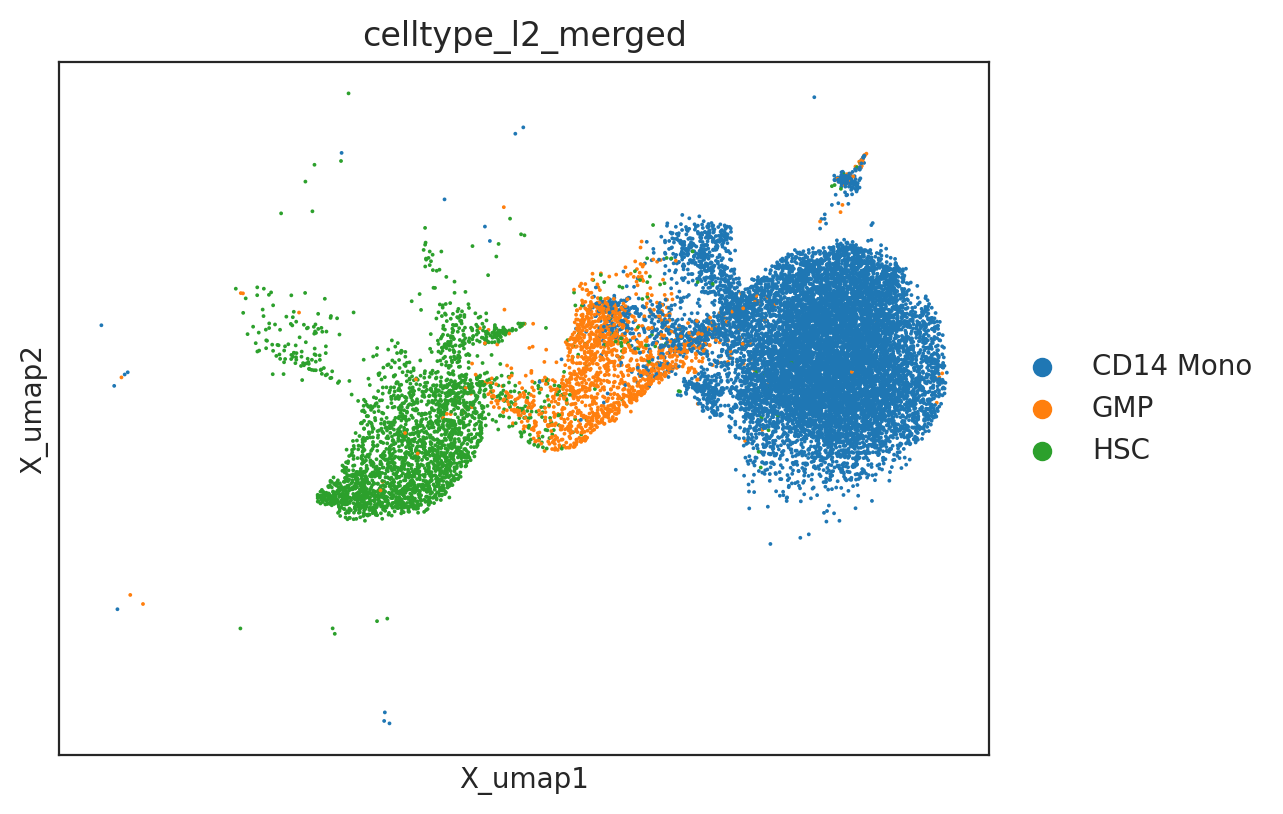

In [21]:
# Instantiate Oracle object.
oracle.import_anndata_as_raw_count(adata=adata_co,
                                   cluster_column_name="celltype_l2_merged",
                                   embedding_name="X_umap")

## load TF

In [22]:
oracle.import_TF_data(TF_info_matrix=base_GRN)

In [23]:
oracle

Oracle object

Meta data
    celloracle version used for instantiation: 0.22.0
    n_cells: 16045
    n_genes: 3000
    cluster_name: celltype_l2_merged
    dimensional_reduction_name: X_umap
    n_target_genes_in_TFdict: 27150 genes
    n_regulatory_in_TFdict: 1094 genes
    n_regulatory_in_both_TFdict_and_scRNA-seq: 137 genes
    n_target_genes_both_TFdict_and_scRNA-seq: 2582 genes
    k_for_knn_imputation: NA
Status
    Gene expression matrix: Ready
    BaseGRN: Ready
    PCA calculation: Not finished
    Knn imputation: Not finished
    GRN calculation for simulation: Not finished

#  KNN imputation

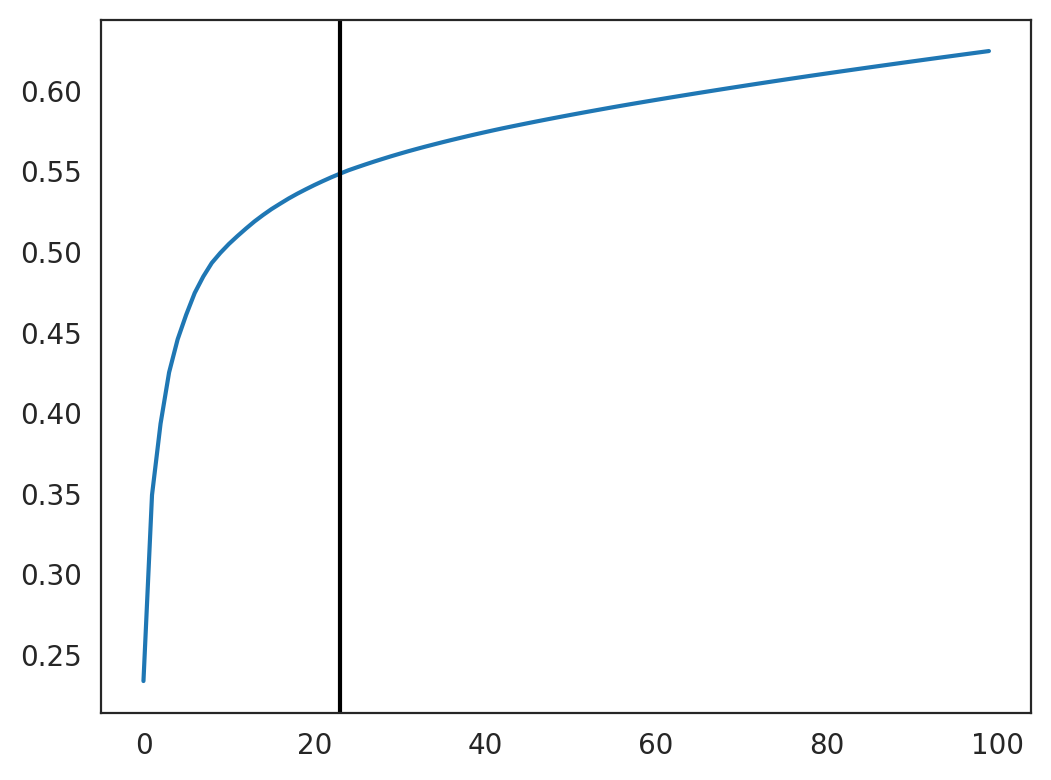

23


In [24]:
# Perform PCA
oracle.perform_PCA()

# Select important PCs
plt.plot(np.cumsum(oracle.pca.explained_variance_ratio_)[:100])
n_comps = np.where(np.diff(np.diff(np.cumsum(oracle.pca.explained_variance_ratio_))>0.002))[0][0]
plt.axvline(n_comps, c="k")
plt.show()
print(n_comps)
n_comps = min(n_comps, 50)

## knn imputation

In [25]:
n_cell = oracle.adata.shape[0]
print(f"cell number is :{n_cell}")

cell number is :16045


In [26]:
k = int(0.025*n_cell)
print(f"Auto-selected k is :{k}")

Auto-selected k is :401


In [27]:
oracle.knn_imputation(n_pca_dims=n_comps, k=k, balanced=True, b_sight=k*8,
                      b_maxl=k*4, n_jobs=4)

# Save oracle object

In [28]:
# Save oracle object.
oracle.to_hdf5("adata.celloracle.oracle")

In [29]:
# Load file.
oracle = co.load_hdf5("adata.celloracle.oracle")

# GRN calculation

## Get GRNs

In [31]:
CELLTYPE_COL = "celltype_l2_merged"
CONDITION_COL = "sample_groups_wide"
GRN_COL = "celltype_condition"

obs = oracle.adata.obs

if obs[[CELLTYPE_COL, CONDITION_COL]].isna().any().any():
    raise ValueError("В колонках типа клеток или условия есть пропуски.")

oracle.adata.obs[GRN_COL] = (
    obs[CELLTYPE_COL].astype(str)
    + "__"
    + obs[CONDITION_COL].astype(str)
).astype("category")

# Проверяем группы и число клеток
print(oracle.adata.obs[GRN_COL].value_counts())

CD14 Mono__JMML       10793
HSC__JMML              2444
GMP__JMML              1320
CD14 Mono__Control      999
HSC__Control            255
GMP__Control            234
Name: celltype_condition, dtype: int64


  0%|          | 0/6 [00:00<?, ?it/s]

Inferring GRN for CD14 Mono__Control...


  0%|          | 0/2582 [00:00<?, ?it/s]

Inferring GRN for CD14 Mono__JMML...


  0%|          | 0/2582 [00:00<?, ?it/s]

...

Inferring GRN for HSC__Control...


  0%|          | 0/2582 [00:00<?, ?it/s]

Inferring GRN for HSC__JMML...


  0%|          | 0/2582 [00:00<?, ?it/s]

/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/gimmemotifs/__init__.py:30: UserWarning: Color information for the celltype_condition is not found in the anndata. CellOracle is plotting the clustering data, celltype_condition, to create color data.
  _warn(*args, **kwargs)
/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/matplotlib/__init__.py:1446: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  return func(ax, *map(sanitize_sequence, args), **kwargs)


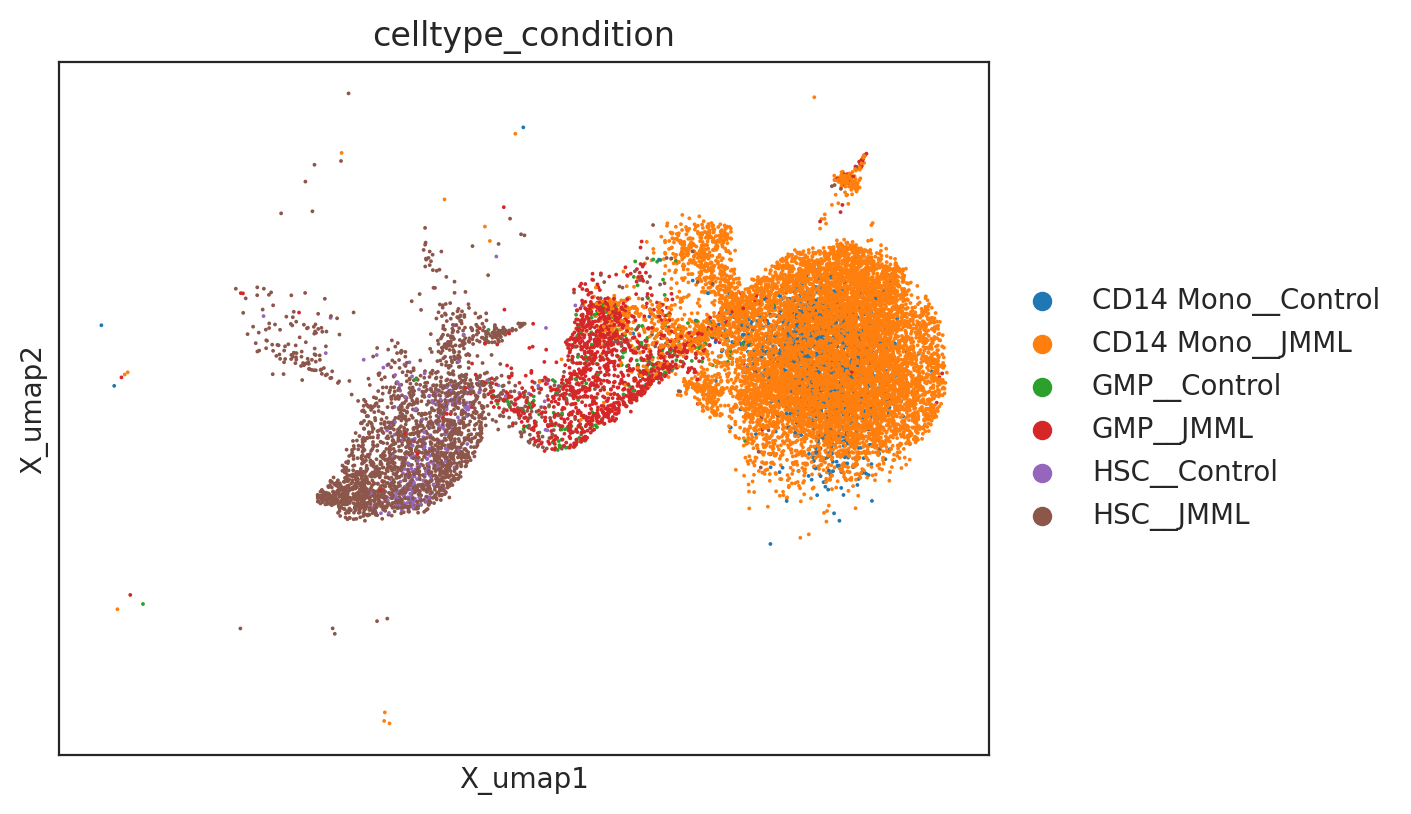

In [32]:
links_condition = oracle.get_links(
    cluster_name_for_GRN_unit=GRN_COL,
    alpha=10,
    verbose_level=10,
)

# Используйте те же параметры фильтрации, что и в исходном анализе
links_condition.filter_links(
    p=0.001,
    weight="coef_abs",
    threshold_number=2000,
)

# Рассчитать centrality и другие сетевые показатели
links_condition.get_network_score()

In [33]:
print(list(links_condition.links_dict.keys()))

['CD14 Mono__Control', 'CD14 Mono__JMML', 'GMP__Control', 'GMP__JMML', 'HSC__Control', 'HSC__JMML']


# Calculate netowrk score

In [37]:
# Calculate network scores. 
# links.get_network_score()
links_condition.get_network_score()


In [38]:
# links.merged_score.head()

In [39]:
links_condition.merged_score.head()


,degree_all,degree_centrality_all,degree_in,degree_centrality_in,degree_out,degree_centrality_out,betweenness_centrality,eigenvector_centrality,cluster
CEBPB,79,0.203085,11,0.028278,68,0.174807,586.0,0.539185,CD14 Mono__Control
HLA-DRA,7,0.017995,7,0.017995,0,0.000000,0.0,0.163192,CD14 Mono__Control
TYROBP,5,0.012853,5,0.012853,0,0.000000,0.0,0.148875,CD14 Mono__Control
KLF4,47,0.120823,7,0.017995,40,0.102828,463.0,0.489405,CD14 Mono__Control
HBB,14,0.035990,14,0.035990,0,0.000000,0.0,0.382728,CD14 Mono__Control


In [ ]:
links_condition.merged_score.to_csv('celloracle_metrics.csv')

In [ ]:
# Save processed GRNs. We will use this file during the in in silico TF perturbation analysis.

In [40]:
# Save Links object.
links_condition.to_hdf5(file_path="Cond_links.celloracle.links")

In [75]:
# Check cluster name
links.cluster

['CD14 Mono', 'GMP', 'HSC']

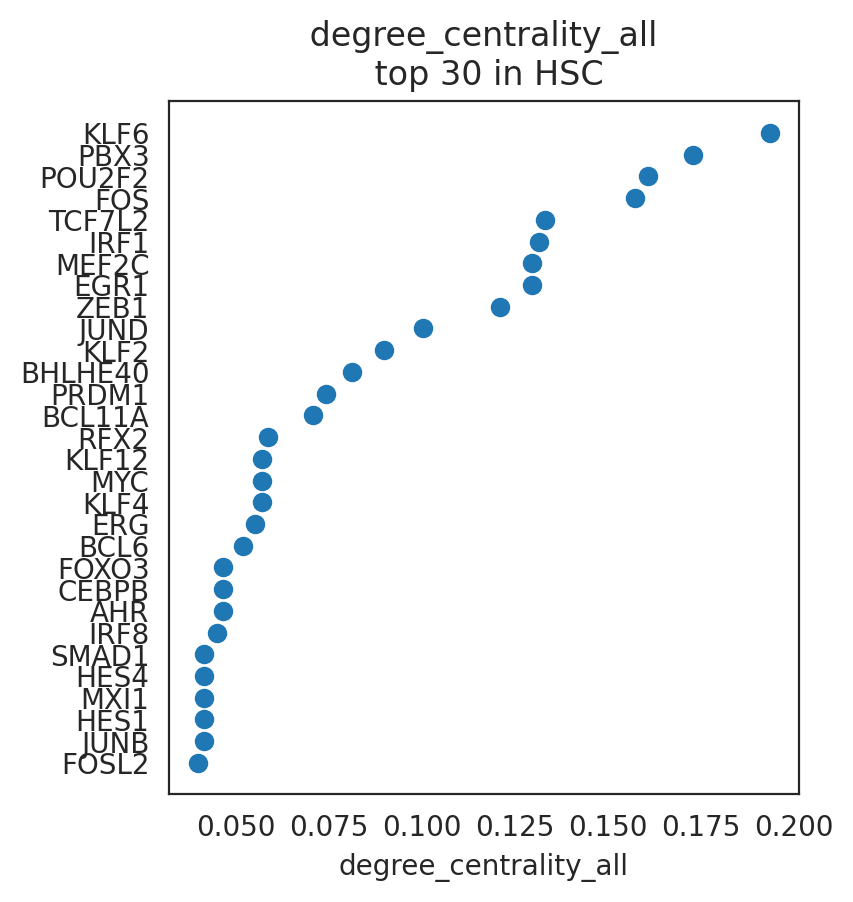

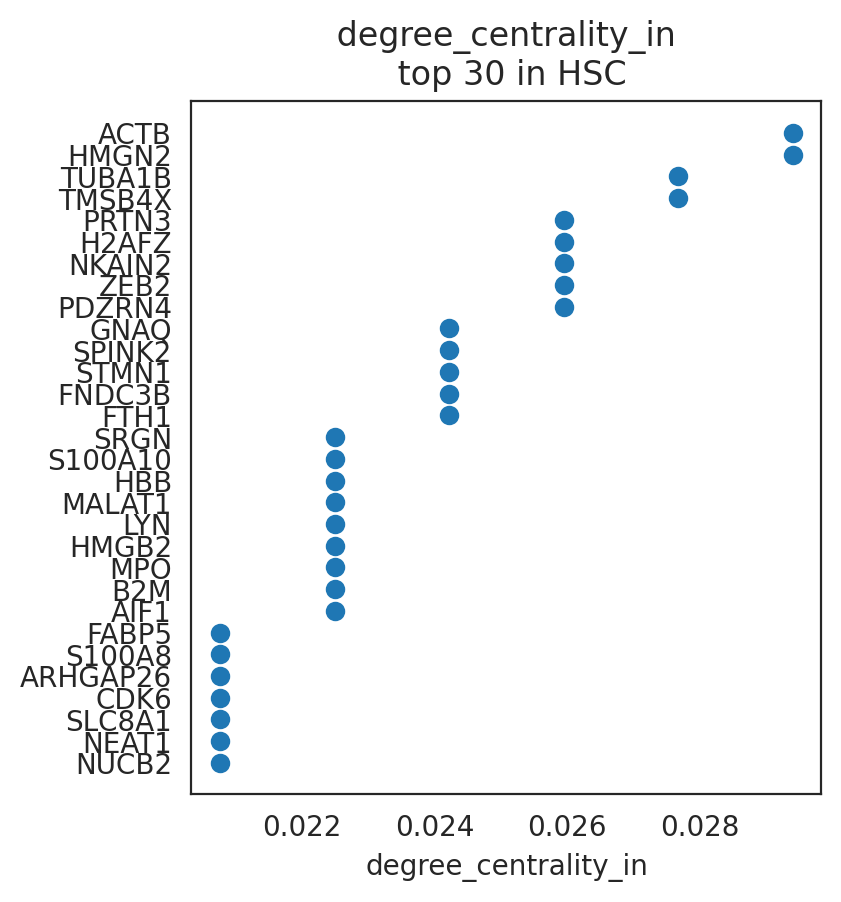

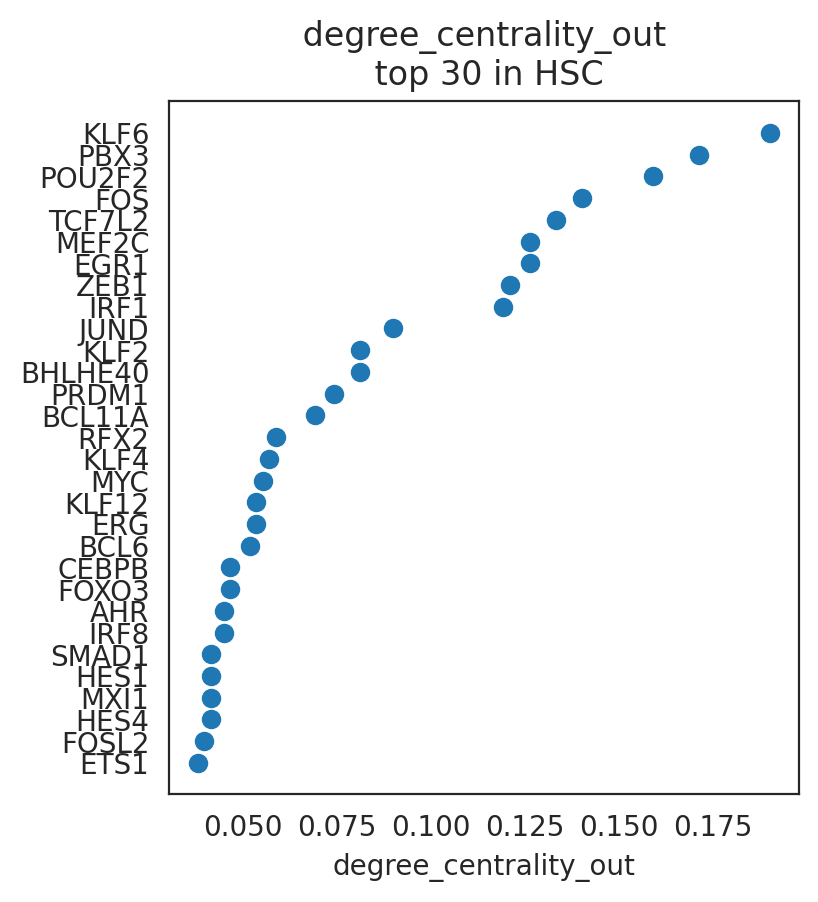

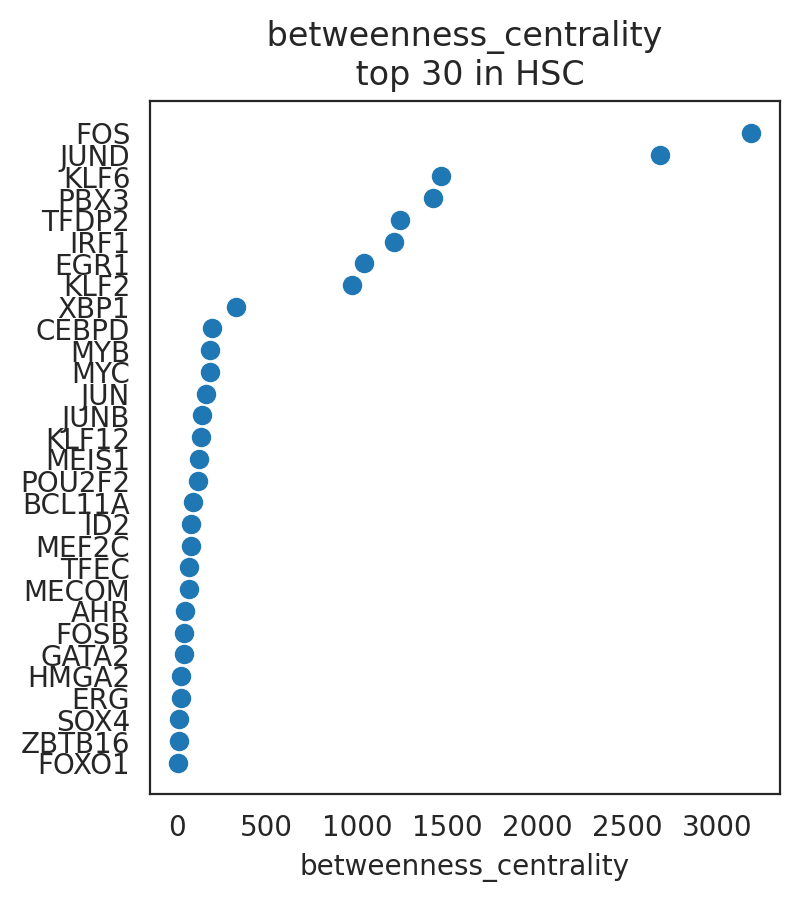

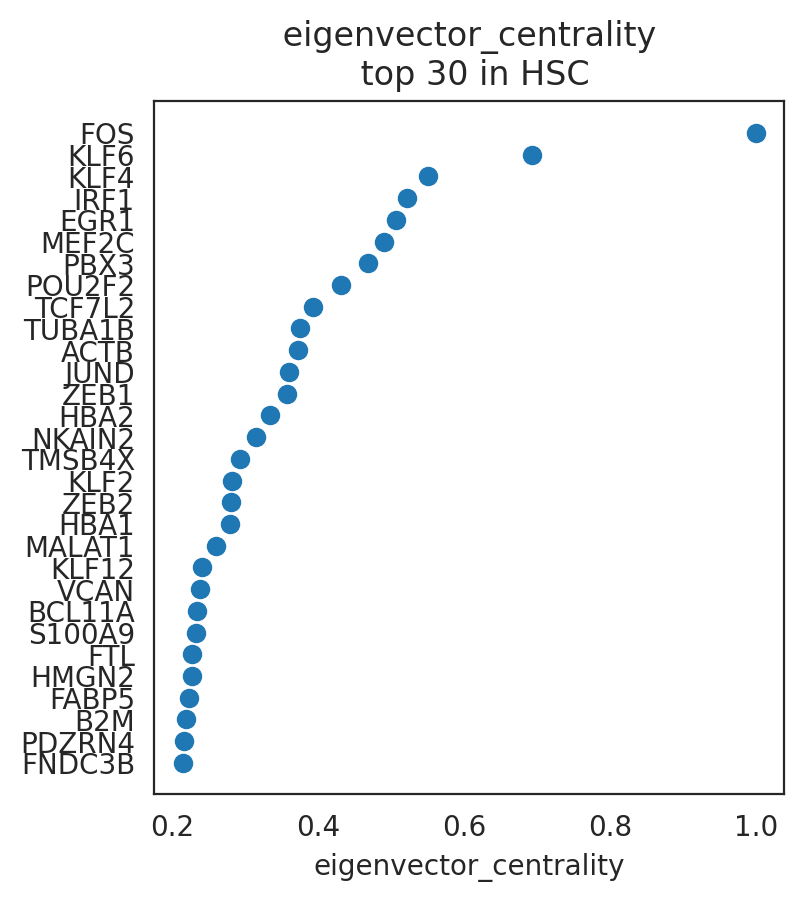

In [77]:
# Visualize top n-th genes with high scores.
links.plot_scores_as_rank(cluster="HSC", n_gene=30, )#save=f"{save_folder}/ranked_score")

In [41]:
print(list(links_condition.links_dict.keys()))

['CD14 Mono__Control', 'CD14 Mono__JMML', 'GMP__Control', 'GMP__JMML', 'HSC__Control', 'HSC__JMML']


In [42]:
links_condition.merged_score.head()

,degree_all,degree_centrality_all,degree_in,degree_centrality_in,degree_out,degree_centrality_out,betweenness_centrality,eigenvector_centrality,cluster
CEBPB,79,0.203085,11,0.028278,68,0.174807,586.0,0.539185,CD14 Mono__Control
HLA-DRA,7,0.017995,7,0.017995,0,0.000000,0.0,0.163192,CD14 Mono__Control
TYROBP,5,0.012853,5,0.012853,0,0.000000,0.0,0.148875,CD14 Mono__Control
KLF4,47,0.120823,7,0.017995,40,0.102828,463.0,0.489405,CD14 Mono__Control
HBB,14,0.035990,14,0.035990,0,0.000000,0.0,0.382728,CD14 Mono__Control


In [103]:
# links_condition.merged_score.to_csv('celloracle_graph_metrics.csv')


# eigenvector_centrality graphs

['CD14 Mono__Control', 'CD14 Mono__JMML', 'GMP__Control', 'GMP__JMML', 'HSC__Control', 'HSC__JMML']


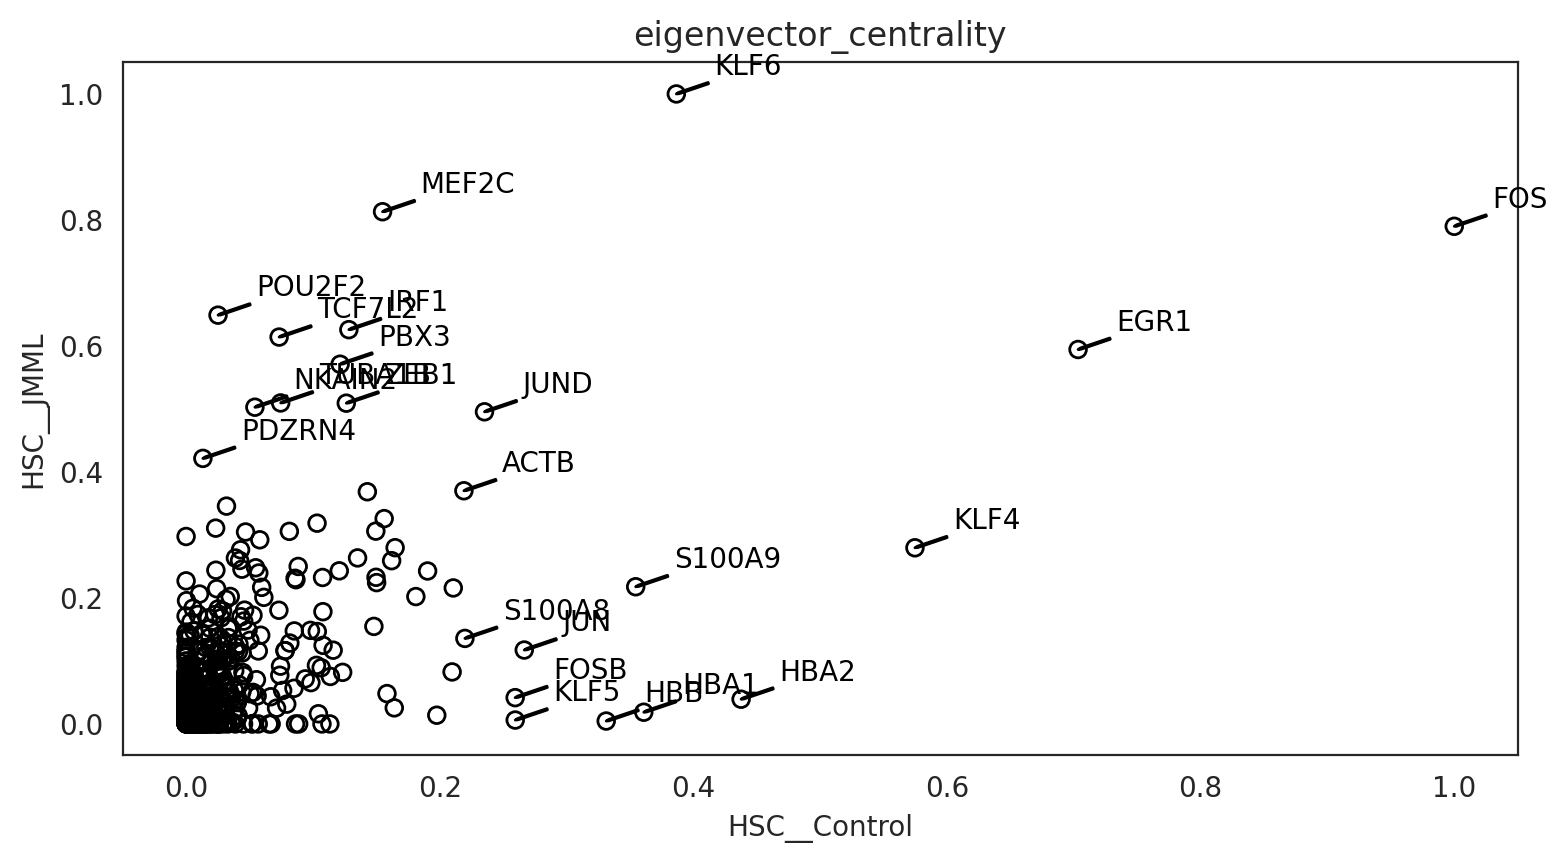

In [43]:
print(list(links_condition.links_dict.keys()))

links_condition.plot_score_comparison_2D(
    value="eigenvector_centrality",
    cluster1="HSC__Control",
    cluster2="HSC__JMML",
    percentile=98,
)
    

['CD14 Mono__Control', 'CD14 Mono__JMML', 'GMP__Control', 'GMP__JMML', 'HSC__Control', 'HSC__JMML']


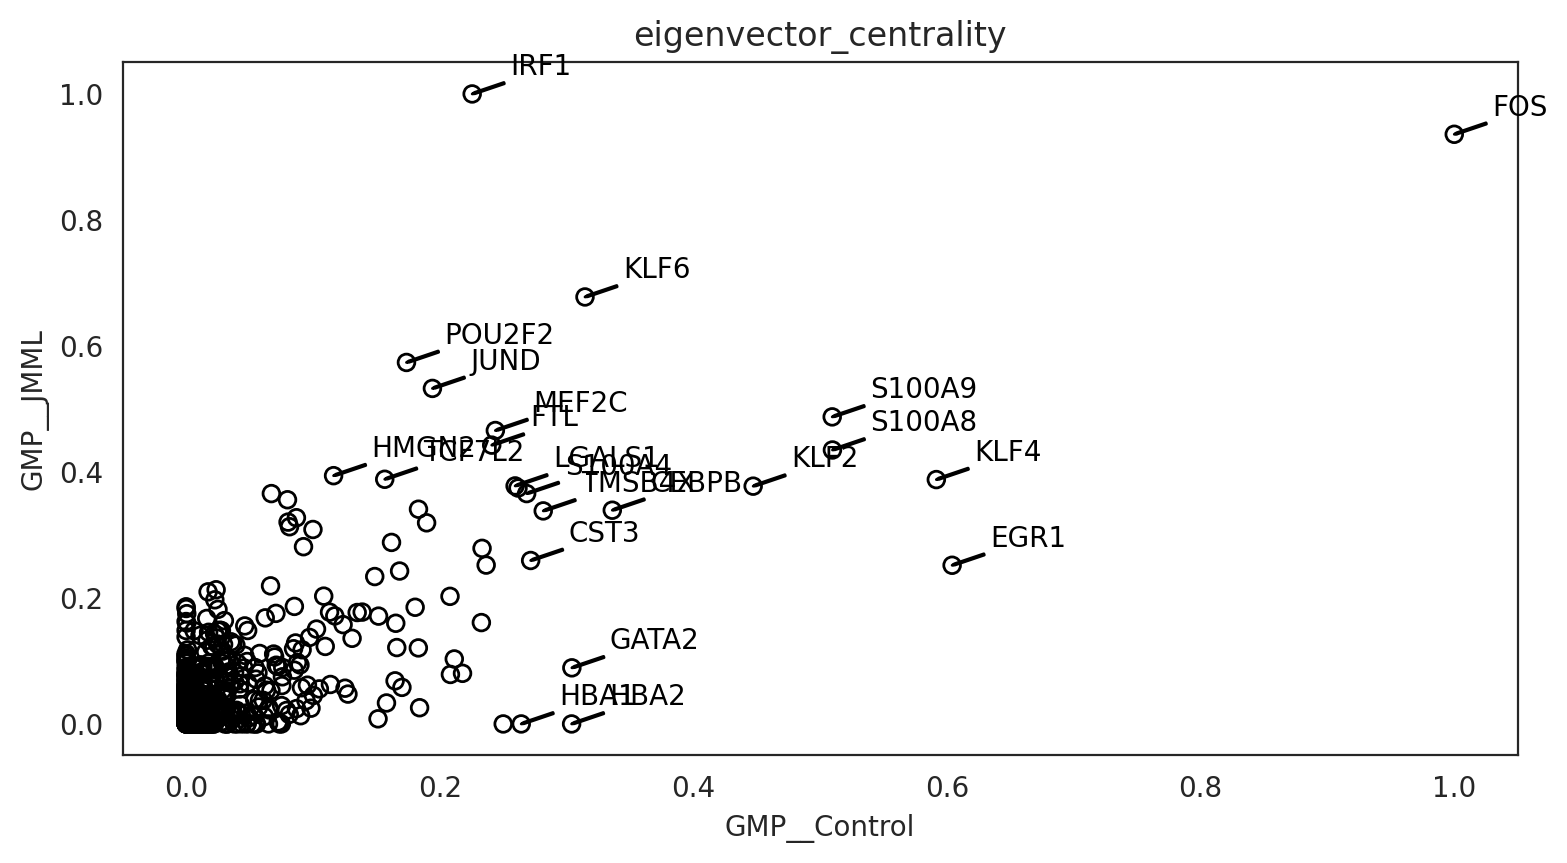

In [44]:
print(list(links_condition.links_dict.keys()))

links_condition.plot_score_comparison_2D(
    value="eigenvector_centrality",
    cluster1="GMP__Control",
    cluster2="GMP__JMML",
    percentile=98,
)
    

['CD14 Mono__Control', 'CD14 Mono__JMML', 'GMP__Control', 'GMP__JMML', 'HSC__Control', 'HSC__JMML']


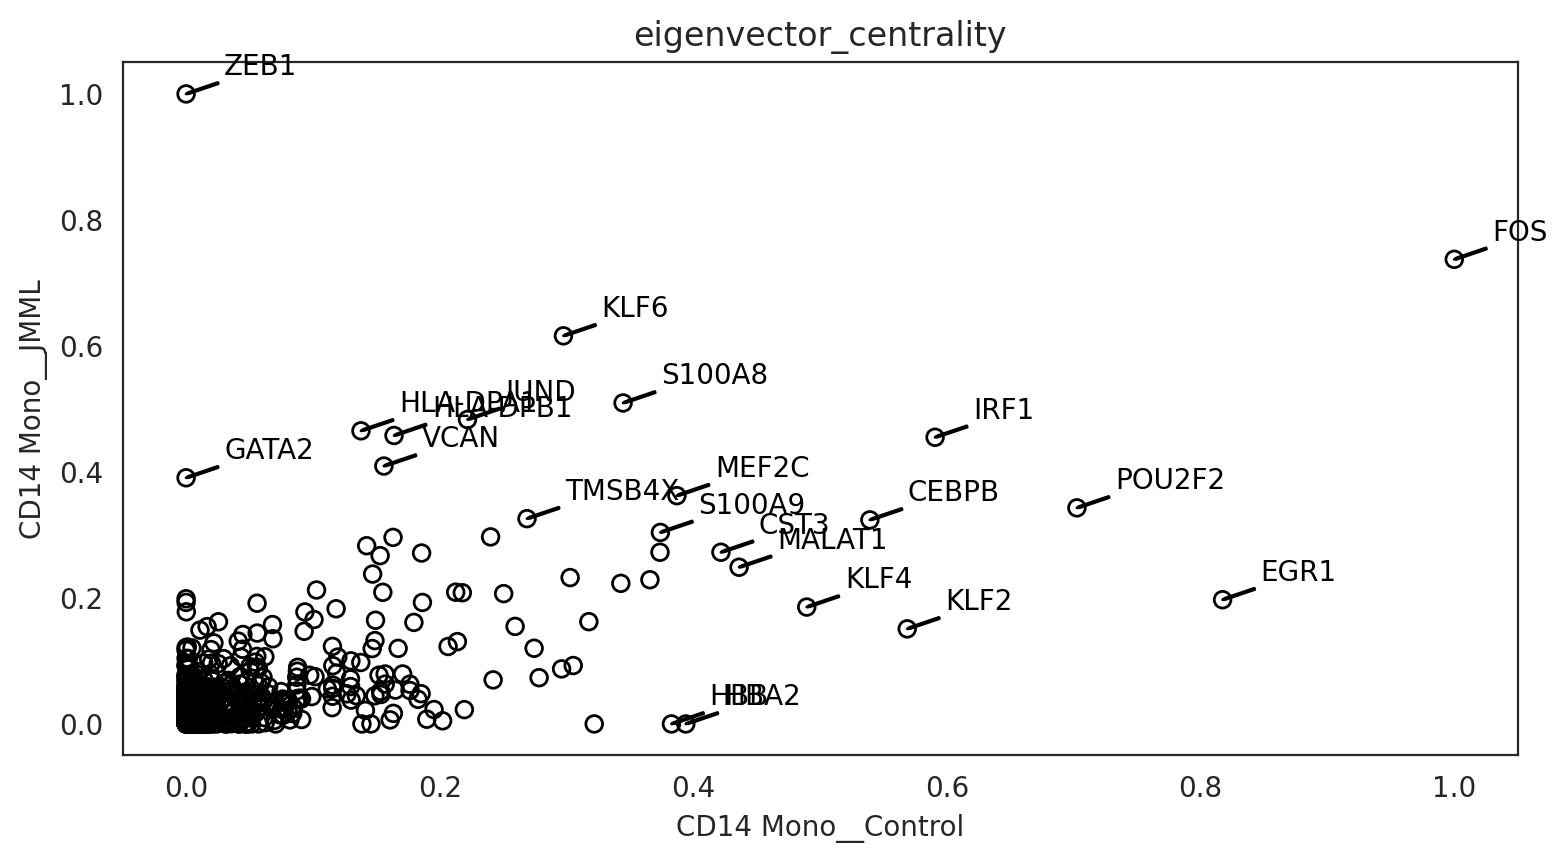

In [45]:
print(list(links_condition.links_dict.keys()))

links_condition.plot_score_comparison_2D(
    value="eigenvector_centrality",
    cluster1="CD14 Mono__Control",
    cluster2="CD14 Mono__JMML",
    percentile=98,
)
    

In [137]:
cluster_name = "CD14 Mono__Control"
filtered_links_df = links_condition.filtered_links[cluster_name]
filtered_links_df.head()

,source,target,coef_mean,coef_abs,p,-logp
80177,CEBPB,TYROBP,0.890996,0.890996,1.399106e-20,19.854149
33106,CEBPB,HLA-DRA,0.871076,0.871076,5.556451e-15,14.255203
31569,KLF4,HBB,0.841783,0.841783,5.484909e-13,12.260831
3869,MXI1,ANXA1,0.763152,0.763152,9.167859e-14,13.037732
31575,EGR1,HBB,0.736888,0.736888,1.885721e-09,8.724523


In [138]:
filtered_links_df.set_index('source', inplace=True)

In [139]:
filtered_links_df[filtered_links_df.index=='ZEB1']

,target,coef_mean,coef_abs,p,-logp
source,,,,,


# ОТбор мишеней по Celloracle graph metrics

### HSC old

In [203]:
# # import pandas as pd

# metric = "eigenvector_centrality"
# control = "HSC__Control"
# jmml = "HSC__JMML"

# scores = links_condition.merged_score.copy()

# # Gene names are in the index in the standard CellOracle output.
# scores = scores.rename_axis("gene").reset_index()

# wide = (
#     scores.loc[
#         scores["cluster"].isin([control, jmml]),
#         ["gene", "cluster", metric]
#     ]
#     .pivot(index="gene", columns="cluster", values=metric)
#     .reindex(columns=[control, jmml])
#     .rename(columns={control: "Control", jmml: "JMML"})
# )

# # Preserve genes absent from one network for separate inspection.
# missing_scores = wide.loc[wide.isna().any(axis=1)].copy()

# # Main comparison: genes with calculated scores in both networks.
# comparison = wide.dropna(subset=["Control", "JMML"]).copy()

# # Percentile ranks within the same comparison gene universe.
# comparison["rank_Control"] = comparison["Control"].rank(
#     method="average", pct=True
# )
# comparison["rank_JMML"] = comparison["JMML"].rank(
#     method="average", pct=True
# )

# comparison["delta_score"] = (
#     comparison["JMML"] - comparison["Control"]
# )
# comparison["delta_rank"] = (
#     comparison["rank_JMML"] - comparison["rank_Control"]
# )

# # Exploratory thresholds, not statistical significance.
# comparison["selected"] = (
#     (comparison["JMML"] > 0)
#     & (comparison["rank_JMML"] >= 0.80)
#     & (comparison["delta_rank"] >= 0.20)
#     & (comparison["delta_score"] > 0)
# )

# candidates_HSC = (
#     comparison.loc[comparison["selected"]]
#     .sort_values(
#         ["delta_rank", "rank_JMML"],
#         ascending=False
#     )
# )

# print(candidates_HSC.head(30))

# # comparison.to_csv("HSC_eigenvector_comparison.csv")
# # candidates.to_csv("HSC_JMML_candidates.csv")
# # missing_scores.to_csv("HSC_genes_missing_network_scores.csv")


In [204]:
# candidates_HSC

### GMP old

In [205]:
# # import pandas as pd

# metric = "eigenvector_centrality"
# control = "GMP__Control"
# jmml = "GMP__JMML"

# scores = links_condition.merged_score.copy()

# # Gene names are in the index in the standard CellOracle output.
# scores = scores.rename_axis("gene").reset_index()

# wide = (
#     scores.loc[
#         scores["cluster"].isin([control, jmml]),
#         ["gene", "cluster", metric]
#     ]
#     .pivot(index="gene", columns="cluster", values=metric)
#     .reindex(columns=[control, jmml])
#     .rename(columns={control: "Control", jmml: "JMML"})
# )

# # Preserve genes absent from one network for separate inspection.
# missing_scores = wide.loc[wide.isna().any(axis=1)].copy()

# # Main comparison: genes with calculated scores in both networks.
# comparison = wide.dropna(subset=["Control", "JMML"]).copy()

# # Percentile ranks within the same comparison gene universe.
# comparison["rank_Control"] = comparison["Control"].rank(
#     method="average", pct=True
# )
# comparison["rank_JMML"] = comparison["JMML"].rank(
#     method="average", pct=True
# )

# comparison["delta_score"] = (
#     comparison["JMML"] - comparison["Control"]
# )
# comparison["delta_rank"] = (
#     comparison["rank_JMML"] - comparison["rank_Control"]
# )

# # Exploratory thresholds, not statistical significance.
# comparison["selected"] = (
#     (comparison["JMML"] > 0)
#     & (comparison["rank_JMML"] >= 0.80)
#     & (comparison["delta_rank"] >= 0.20)
#     & (comparison["delta_score"] > 0)
# )

# candidates_GMP = (
#     comparison.loc[comparison["selected"]]
#     .sort_values(
#         ["delta_rank", "rank_JMML"],
#         ascending=False
#     )
# )

# # print(candidates_GMP.head(30))

# # comparison.to_csv("HSC_eigenvector_comparison.csv")
# # candidates.to_csv("HSC_JMML_candidates.csv")
# # missing_scores.to_csv("HSC_genes_missing_network_scores.csv")


In [206]:
# candidates_GMP

### CD14 Mono

In [207]:
# # import pandas as pd

# metric = "eigenvector_centrality"
# control = "CD14 Mono__Control"
# jmml = "CD14 Mono__JMML"

# scores = links_condition.merged_score.copy()

# # Gene names are in the index in the standard CellOracle output.
# scores = scores.rename_axis("gene").reset_index()

# wide = (
#     scores.loc[
#         scores["cluster"].isin([control, jmml]),
#         ["gene", "cluster", metric]
#     ]
#     .pivot(index="gene", columns="cluster", values=metric)
#     .reindex(columns=[control, jmml])
#     .rename(columns={control: "Control", jmml: "JMML"})
# )

# # Preserve genes absent from one network for separate inspection.
# missing_scores = wide.loc[wide.isna().any(axis=1)].copy()

# # Main comparison: genes with calculated scores in both networks.
# # comparison = wide.dropna(subset=["Control", "JMML"]).copy()
# comparison = wide.copy()


# # Percentile ranks within the same comparison gene universe.
# comparison["rank_Control"] = comparison["Control"].rank(
#     method="average", pct=True
# )
# comparison["rank_JMML"] = comparison["JMML"].rank(
#     method="average", pct=True
# )

# comparison["delta_score"] = (
#     comparison["JMML"] - comparison["Control"]
# )
# comparison["delta_rank"] = (
#     comparison["rank_JMML"] - comparison["rank_Control"]
# )

# # Exploratory thresholds, not statistical significance.
# comparison["selected"] = (
#     (comparison["JMML"] > 0)
#     & (comparison["rank_JMML"] >= 0.80)
#     # & (comparison["delta_rank"] >= 0.10)
#     & (comparison["delta_score"] > 0)
# )

# candidates_CD14_Mono = (
#     comparison.loc[comparison["selected"]]
#     .sort_values(
#         ["delta_rank", "rank_JMML"],
#         ascending=False
#     )
# )

# # print(candidates_CD14_Mono.head(30))

# # comparison.to_csv("HSC_eigenvector_comparison.csv")
# # candidates.to_csv("HSC_JMML_candidates.csv")
# # missing_scores.to_csv("HSC_genes_missing_network_scores.csv")


In [208]:
# len(candidates_CD14_Mono.index)

In [175]:
# [x for x in candidates_CD14_Mono.index if 'Z' in x]


['NFKBIZ', 'LYZ']

In [209]:
# candidates_CD14_Mono

## CD14 final candidates

In [188]:
# ---------- Настройки ----------
CELLTYPE = "CD14 Mono"  # Также: "HSC", "GMP"
METRIC = "eigenvector_centrality"

CONTROL = f"{CELLTYPE}__Control"
JMML = f"{CELLTYPE}__JMML"

TOP_N = 30
MIN_JMML_RANK = 0.90
MIN_DELTA_RANK = 0.20

# ---------- Загрузка ----------
metrics = pd.read_csv("celloracle_graph_metrics.csv")
metrics = metrics.rename(columns={"Unnamed: 0": "gene"})

required_columns = {"gene", "cluster", METRIC}
missing_columns = required_columns.difference(metrics.columns)

if missing_columns:
    raise ValueError(f"В CSV отсутствуют колонки: {missing_columns}")

available_clusters = set(metrics["cluster"].dropna())

for cluster in [CONTROL, JMML]:
    if cluster not in available_clusters:
        raise ValueError(
            f"Группа {cluster!r} отсутствует. "
            f"Доступные группы: {sorted(available_clusters)}"
        )

# ---------- Объединение по всем генам двух сетей ----------
wide = (
    metrics.loc[
        metrics["cluster"].isin([CONTROL, JMML]),
        ["gene", "cluster", METRIC]
    ]
    .pivot(index="gene", columns="cluster", values=METRIC)
    .reindex(columns=[CONTROL, JMML])
    .rename(columns={
        CONTROL: "Control",
        JMML: "JMML"
    })
)

# ---------- Сохранение исходных пропусков ----------
missing_mask = wide[["Control", "JMML"]].isna()

missing_scores = wide.loc[missing_mask.any(axis=1)].copy()

missing_scores["Control_was_missing"] = (
    missing_mask.loc[missing_scores.index, "Control"]
)
missing_scores["JMML_was_missing"] = (
    missing_mask.loc[missing_scores.index, "JMML"]
)

# ---------- Замена NaN на 0 ----------
comparison = wide.copy()

comparison["Control_was_missing"] = missing_mask["Control"]
comparison["JMML_was_missing"] = missing_mask["JMML"]

comparison[["Control", "JMML"]] = (
    comparison[["Control", "JMML"]].fillna(0)
)

# ---------- Метрики сравнения ----------
# Ранги вычисляются на одном общем наборе генов
# уже после замены пропусков нулями.
comparison["rank_Control"] = comparison["Control"].rank(
    method="average",
    pct=True
)

comparison["rank_JMML"] = comparison["JMML"].rank(
    method="average",
    pct=True
)

comparison["delta_score"] = (
    comparison["JMML"] - comparison["Control"]
)

comparison["delta_rank"] = (
    comparison["rank_JMML"] - comparison["rank_Control"]
)

# ---------- Вариант 1: топ по centrality JMML ----------
top_jmml = (
    comparison.loc[comparison["JMML"] > 0]
    .sort_values("JMML", ascending=False)
    .head(TOP_N)
    .copy()
)

# ---------- Вариант 2: высокий ранг JMML + прирост ранга ----------
# Пороги исследовательские, не статистическая значимость.
comparison["selected_by_rank"] = (
    (comparison["JMML"] > 0)
    & (comparison["rank_JMML"] >= MIN_JMML_RANK)
    # & (comparison["delta_rank"] >= MIN_DELTA_RANK)
    & (comparison["delta_score"] > 0)
)

rank_candidates = (
    comparison.loc[comparison["selected_by_rank"]]
    .sort_values(
        ["delta_rank", "JMML"],
        ascending=False
    )
    .copy()
)

# ---------- Сохранение ----------
prefix = CELLTYPE.replace(" ", "_")

missing_scores.to_csv('../storage/celloracle_candidates/' + f"{prefix}_missing_scores.csv")
comparison.to_csv('../storage/celloracle_candidates/' + f"{prefix}_centrality_comparison_zero_filled.csv")
top_jmml.to_csv('../storage/celloracle_candidates/' + f"{prefix}_top_JMML_centrality.csv")
rank_candidates.to_csv('../storage/celloracle_candidates/' + f"{prefix}_rank_candidates.csv")

# ---------- Проверка ----------
# print(f"Всего генов в объединении: {len(comparison)}")
# print(f"Генов с исходными пропусками: {len(missing_scores)}")

# print("\nТоп по центральности JMML:")
# print(top_jmml.to_string())

# if "ZEB1" in comparison.index:
#     print("\nZEB1 после замены пропусков:")
#     print(comparison.loc[["ZEB1"]].to_string())

In [189]:
! ls ../storage/celloracle_candidates/

CD14_Mono
CD14_Mono_centrality_comparison_zero_filled.csv
CD14_Mono_missing_scores.csv
CD14_Mono_rank_candidates.csv
CD14_Mono_top_JMML_centrality.csv
GMP
HSC


In [190]:
rank_candidates

cluster,Control,JMML,Control_was_missing,JMML_was_missing,rank_Control,rank_JMML,delta_score,delta_rank,selected_by_rank
gene,,,,,,,,,
ZEB1,0.000000,1.000000,True,False,0.186893,1.000000,1.000000,0.813107,True
GATA2,0.000000,0.352721,True,False,0.186893,0.983819,0.352721,0.796926,True
TEX14,0.000000,0.182811,True,False,0.186893,0.941748,0.182811,0.754854,True
ERG,0.000000,0.171555,True,False,0.186893,0.938511,0.171555,0.751618,True
PDE4D,0.000000,0.134674,True,False,0.186893,0.914239,0.134674,0.727346,True
SMAD1,0.000213,0.149022,False,False,0.377023,0.925566,0.148809,0.548544,True
THBS1,0.010603,0.142152,False,False,0.506472,0.920712,0.131549,0.414239,True
BCL11A,0.013727,0.134052,False,False,0.543689,0.912621,0.120325,0.368932,True
CD83,0.025447,0.156727,False,False,0.652104,0.930421,0.131280,0.278317,True


## GMP final candidates

In [191]:
# ---------- Настройки ----------
CELLTYPE = "GMP"  # Также: "HSC", "GMP"
METRIC = "eigenvector_centrality"

CONTROL = f"{CELLTYPE}__Control"
JMML = f"{CELLTYPE}__JMML"

TOP_N = 30
MIN_JMML_RANK = 0.90
MIN_DELTA_RANK = 0.20

# ---------- Загрузка ----------
metrics = pd.read_csv("celloracle_graph_metrics.csv")
metrics = metrics.rename(columns={"Unnamed: 0": "gene"})

required_columns = {"gene", "cluster", METRIC}
missing_columns = required_columns.difference(metrics.columns)

if missing_columns:
    raise ValueError(f"В CSV отсутствуют колонки: {missing_columns}")

available_clusters = set(metrics["cluster"].dropna())

for cluster in [CONTROL, JMML]:
    if cluster not in available_clusters:
        raise ValueError(
            f"Группа {cluster!r} отсутствует. "
            f"Доступные группы: {sorted(available_clusters)}"
        )

# ---------- Объединение по всем генам двух сетей ----------
wide = (
    metrics.loc[
        metrics["cluster"].isin([CONTROL, JMML]),
        ["gene", "cluster", METRIC]
    ]
    .pivot(index="gene", columns="cluster", values=METRIC)
    .reindex(columns=[CONTROL, JMML])
    .rename(columns={
        CONTROL: "Control",
        JMML: "JMML"
    })
)

# ---------- Сохранение исходных пропусков ----------
missing_mask = wide[["Control", "JMML"]].isna()

missing_scores = wide.loc[missing_mask.any(axis=1)].copy()

missing_scores["Control_was_missing"] = (
    missing_mask.loc[missing_scores.index, "Control"]
)
missing_scores["JMML_was_missing"] = (
    missing_mask.loc[missing_scores.index, "JMML"]
)

# ---------- Замена NaN на 0 ----------
comparison = wide.copy()

comparison["Control_was_missing"] = missing_mask["Control"]
comparison["JMML_was_missing"] = missing_mask["JMML"]

comparison[["Control", "JMML"]] = (
    comparison[["Control", "JMML"]].fillna(0)
)

# ---------- Метрики сравнения ----------
# Ранги вычисляются на одном общем наборе генов
# уже после замены пропусков нулями.
comparison["rank_Control"] = comparison["Control"].rank(
    method="average",
    pct=True
)

comparison["rank_JMML"] = comparison["JMML"].rank(
    method="average",
    pct=True
)

comparison["delta_score"] = (
    comparison["JMML"] - comparison["Control"]
)

comparison["delta_rank"] = (
    comparison["rank_JMML"] - comparison["rank_Control"]
)

# ---------- Вариант 1: топ по centrality JMML ----------
top_jmml = (
    comparison.loc[comparison["JMML"] > 0]
    .sort_values("JMML", ascending=False)
    .head(TOP_N)
    .copy()
)

# ---------- Вариант 2: высокий ранг JMML + прирост ранга ----------
# Пороги исследовательские, не статистическая значимость.
comparison["selected_by_rank"] = (
    (comparison["JMML"] > 0)
    & (comparison["rank_JMML"] >= MIN_JMML_RANK)
    # & (comparison["delta_rank"] >= MIN_DELTA_RANK)
    & (comparison["delta_score"] > 0)
)

rank_candidates = (
    comparison.loc[comparison["selected_by_rank"]]
    .sort_values(
        ["delta_rank", "JMML"],
        ascending=False
    )
    .copy()
)

# ---------- Сохранение ----------
prefix = CELLTYPE.replace(" ", "_")

missing_scores.to_csv('../storage/celloracle_candidates/' + f"{prefix}_missing_scores.csv")
comparison.to_csv('../storage/celloracle_candidates/' + f"{prefix}_centrality_comparison_zero_filled.csv")
top_jmml.to_csv('../storage/celloracle_candidates/' + f"{prefix}_top_JMML_centrality.csv")
rank_candidates.to_csv('../storage/celloracle_candidates/' + f"{prefix}_rank_candidates.csv")

# ---------- Проверка ----------
# print(f"Всего генов в объединении: {len(comparison)}")
# print(f"Генов с исходными пропусками: {len(missing_scores)}")

# print("\nТоп по центральности JMML:")
# print(top_jmml.to_string())

# if "ZEB1" in comparison.index:
#     print("\nZEB1 после замены пропусков:")
#     print(comparison.loc[["ZEB1"]].to_string())

In [192]:
rank_candidates

cluster,Control,JMML,Control_was_missing,JMML_was_missing,rank_Control,rank_JMML,delta_score,delta_rank,selected_by_rank
gene,,,,,,,,,
NUSAP1,0.000000,0.190158,True,False,0.187404,0.933948,0.190158,0.746544,True
SLC22A15,0.000000,0.162375,True,False,0.187404,0.907834,0.162375,0.720430,True
PRDM1,0.000000,0.160643,True,False,0.187404,0.906298,0.160643,0.718894,True
PDE4D,0.000084,0.187375,False,False,0.379416,0.930876,0.187292,0.551459,True
ACSM3,0.000432,0.185876,False,False,0.388633,0.929339,0.185445,0.540707,True
MKI67,0.000539,0.157790,False,False,0.391705,0.904762,0.157252,0.513057,True
SAMSN1,0.006522,0.157038,False,False,0.516129,0.901690,0.150516,0.385561,True
RAB32,0.011667,0.163672,False,False,0.576037,0.910906,0.152005,0.334869,True
CTSG,0.015670,0.164347,False,False,0.631336,0.912442,0.148677,0.281106,True


## HSC final candidates

In [193]:
# ---------- Настройки ----------
CELLTYPE = "HSC"  # Также: "HSC", "GMP"
METRIC = "eigenvector_centrality"

CONTROL = f"{CELLTYPE}__Control"
JMML = f"{CELLTYPE}__JMML"

TOP_N = 30
MIN_JMML_RANK = 0.90
MIN_DELTA_RANK = 0.20

# ---------- Загрузка ----------
metrics = pd.read_csv("celloracle_graph_metrics.csv")
metrics = metrics.rename(columns={"Unnamed: 0": "gene"})

required_columns = {"gene", "cluster", METRIC}
missing_columns = required_columns.difference(metrics.columns)

if missing_columns:
    raise ValueError(f"В CSV отсутствуют колонки: {missing_columns}")

available_clusters = set(metrics["cluster"].dropna())

for cluster in [CONTROL, JMML]:
    if cluster not in available_clusters:
        raise ValueError(
            f"Группа {cluster!r} отсутствует. "
            f"Доступные группы: {sorted(available_clusters)}"
        )

# ---------- Объединение по всем генам двух сетей ----------
wide = (
    metrics.loc[
        metrics["cluster"].isin([CONTROL, JMML]),
        ["gene", "cluster", METRIC]
    ]
    .pivot(index="gene", columns="cluster", values=METRIC)
    .reindex(columns=[CONTROL, JMML])
    .rename(columns={
        CONTROL: "Control",
        JMML: "JMML"
    })
)

# ---------- Сохранение исходных пропусков ----------
missing_mask = wide[["Control", "JMML"]].isna()

missing_scores = wide.loc[missing_mask.any(axis=1)].copy()

missing_scores["Control_was_missing"] = (
    missing_mask.loc[missing_scores.index, "Control"]
)
missing_scores["JMML_was_missing"] = (
    missing_mask.loc[missing_scores.index, "JMML"]
)

# ---------- Замена NaN на 0 ----------
comparison = wide.copy()

comparison["Control_was_missing"] = missing_mask["Control"]
comparison["JMML_was_missing"] = missing_mask["JMML"]

comparison[["Control", "JMML"]] = (
    comparison[["Control", "JMML"]].fillna(0)
)

# ---------- Метрики сравнения ----------
# Ранги вычисляются на одном общем наборе генов
# уже после замены пропусков нулями.
comparison["rank_Control"] = comparison["Control"].rank(
    method="average",
    pct=True
)

comparison["rank_JMML"] = comparison["JMML"].rank(
    method="average",
    pct=True
)

comparison["delta_score"] = (
    comparison["JMML"] - comparison["Control"]
)

comparison["delta_rank"] = (
    comparison["rank_JMML"] - comparison["rank_Control"]
)

# ---------- Вариант 1: топ по centrality JMML ----------
top_jmml = (
    comparison.loc[comparison["JMML"] > 0]
    .sort_values("JMML", ascending=False)
    .head(TOP_N)
    .copy()
)

# ---------- Вариант 2: высокий ранг JMML + прирост ранга ----------
# Пороги исследовательские, не статистическая значимость.
comparison["selected_by_rank"] = (
    (comparison["JMML"] > 0)
    & (comparison["rank_JMML"] >= MIN_JMML_RANK)
    # & (comparison["delta_rank"] >= MIN_DELTA_RANK)
    & (comparison["delta_score"] > 0)
)

rank_candidates = (
    comparison.loc[comparison["selected_by_rank"]]
    .sort_values(
        ["delta_rank", "JMML"],
        ascending=False
    )
    .copy()
)

# ---------- Сохранение ----------
prefix = CELLTYPE.replace(" ", "_")

missing_scores.to_csv('../storage/celloracle_candidates/' + f"{prefix}_missing_scores.csv")
comparison.to_csv('../storage/celloracle_candidates/' + f"{prefix}_centrality_comparison_zero_filled.csv")
top_jmml.to_csv('../storage/celloracle_candidates/' + f"{prefix}_top_JMML_centrality.csv")
rank_candidates.to_csv('../storage/celloracle_candidates/' + f"{prefix}_rank_candidates.csv")

# ---------- Проверка ----------
# print(f"Всего генов в объединении: {len(comparison)}")
# print(f"Генов с исходными пропусками: {len(missing_scores)}")

# print("\nТоп по центральности JMML:")
# print(top_jmml.to_string())

# if "ZEB1" in comparison.index:
#     print("\nZEB1 после замены пропусков:")
#     print(comparison.loc[["ZEB1"]].to_string())

In [194]:
rank_candidates

cluster,Control,JMML,Control_was_missing,JMML_was_missing,rank_Control,rank_JMML,delta_score,delta_rank,selected_by_rank
gene,,,,,,,,,
SETBP1,0.000000,0.309805,True,False,0.175150,0.970060,0.309805,0.794910,True
PLXDC2,0.000000,0.234323,True,False,0.175150,0.938623,0.234323,0.763473,True
BCL6,0.000000,0.192446,True,False,0.175150,0.917665,0.192446,0.742515,True
SLC24A3,0.000000,0.171373,True,False,0.175150,0.901198,0.171373,0.726048,True
MLLT3,0.000310,0.196525,False,False,0.359281,0.920659,0.196216,0.561377,True
...,...,...,...,...,...,...,...,...,...
PLCB1,0.106851,0.188403,False,False,0.937126,0.914671,0.081553,-0.022455,True
LGALS1,0.155302,0.235168,False,False,0.968563,0.940120,0.079866,-0.028443,True
HLA-DRA,0.111155,0.180085,False,False,0.941617,0.908683,0.068930,-0.032934,True


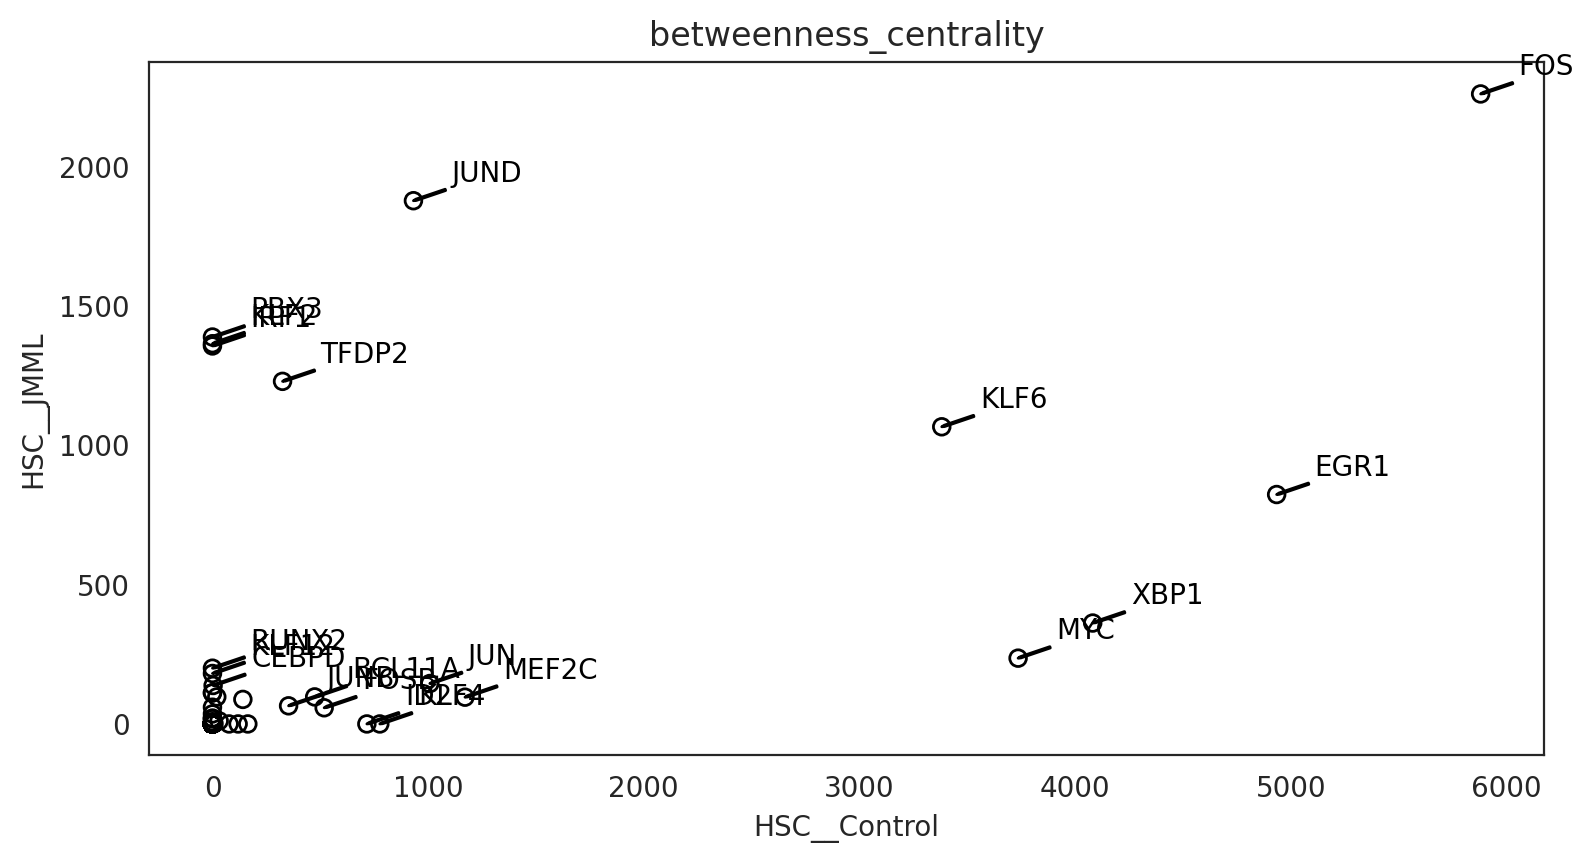

In [120]:
# Compare GRN score between two clusters
links_condition.plot_score_comparison_2D(value="betweenness_centrality",
                               cluster1="HSC__Control", cluster2="HSC__JMML", 
                               percentile=98, )
                              # save=f"{save_folder}/score_comparison")

In [108]:
links_condition.links_dict["HSC__Control"]

,source,target,coef_mean,coef_abs,p,-logp
0,MEF2C,A2M,0.003565,0.003565,9.699997e-12,11.013228
1,IRF9,A2M,0.000947,0.000947,4.408481e-05,4.355711
2,IRF8,A2M,-0.001981,0.001981,2.719230e-05,4.565554
3,PAX5,A2M,0.001672,0.001672,3.770359e-09,8.423617
4,IRF1,A2M,0.001676,0.001676,5.933120e-07,6.226717
...,...,...,...,...,...,...
84397,FOS,ZSWIM6,-0.038811,0.038811,1.586174e-18,17.799649
84398,PAX5,ZSWIM6,0.010020,0.010020,6.369664e-09,8.195883
84399,HES1,ZSWIM6,-0.009629,0.009629,3.283213e-08,7.483701
84400,RUNX2,ZSWIM6,0.010096,0.010096,9.765750e-11,10.010294


In [110]:
links_condition.links_dict["HSC__JMML"]


,source,target,coef_mean,coef_abs,p,-logp
0,MEF2C,A2M,0.006831,0.006831,5.995599e-02,1.222167
1,IRF9,A2M,0.070176,0.070176,2.366594e-09,8.625876
2,IRF8,A2M,-0.033991,0.033991,5.066235e-08,7.295315
3,PAX5,A2M,0.013434,0.013434,3.119006e-10,9.505984
4,IRF1,A2M,-0.026064,0.026064,6.666472e-05,4.176104
...,...,...,...,...,...,...
84397,FOS,ZSWIM6,-0.024503,0.024503,4.514003e-04,3.345438
84398,PAX5,ZSWIM6,0.001934,0.001934,4.175697e-01,0.379271
84399,HES1,ZSWIM6,0.001887,0.001887,8.033624e-01,0.095089
84400,RUNX2,ZSWIM6,-0.006577,0.006577,2.840037e-01,0.546676


In [114]:
CD14_Mono__JMML_df = links_condition.links_dict["CD14 Mono__JMML"].copy()
CD14_Mono__JMML_df.set_index('source', inplace=True)

In [115]:
CD14_Mono__JMML_df

,target,coef_mean,coef_abs,p,-logp
source,,,,,
MEF2C,A2M,0.000127,0.000127,7.696804e-01,0.113690
IRF9,A2M,0.000526,0.000526,8.827710e-02,1.054152
IRF8,A2M,0.000472,0.000472,6.820317e-03,2.166195
PAX5,A2M,0.002690,0.002690,3.326465e-17,16.478017
IRF1,A2M,-0.000555,0.000555,5.073427e-02,1.294699
...,...,...,...,...,...
FOS,ZSWIM6,-0.102191,0.102191,2.358180e-05,4.627423
PAX5,ZSWIM6,0.013899,0.013899,6.185106e-02,1.208653
HES1,ZSWIM6,0.023095,0.023095,9.367206e-02,1.028390


In [126]:
CD14_Mono__JMML_df[CD14_Mono__JMML_df.index=='ZEB1'].p<0.05


source
ZEB1     True
ZEB1    False
ZEB1     True
ZEB1     True
ZEB1     True
        ...  
ZEB1     True
ZEB1     True
ZEB1     True
ZEB1     True
ZEB1     True
Name: p, Length: 1610, dtype: bool

degree_centrality_all


/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/seaborn/categorical.py:1622: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  hue_order = p._palette_without_hue_backcompat(palette, hue_order)
/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/seaborn/categorical.py:1626: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  p.map_hue(palette=palette, order=hue_order, norm=hue_norm, saturation=saturation)


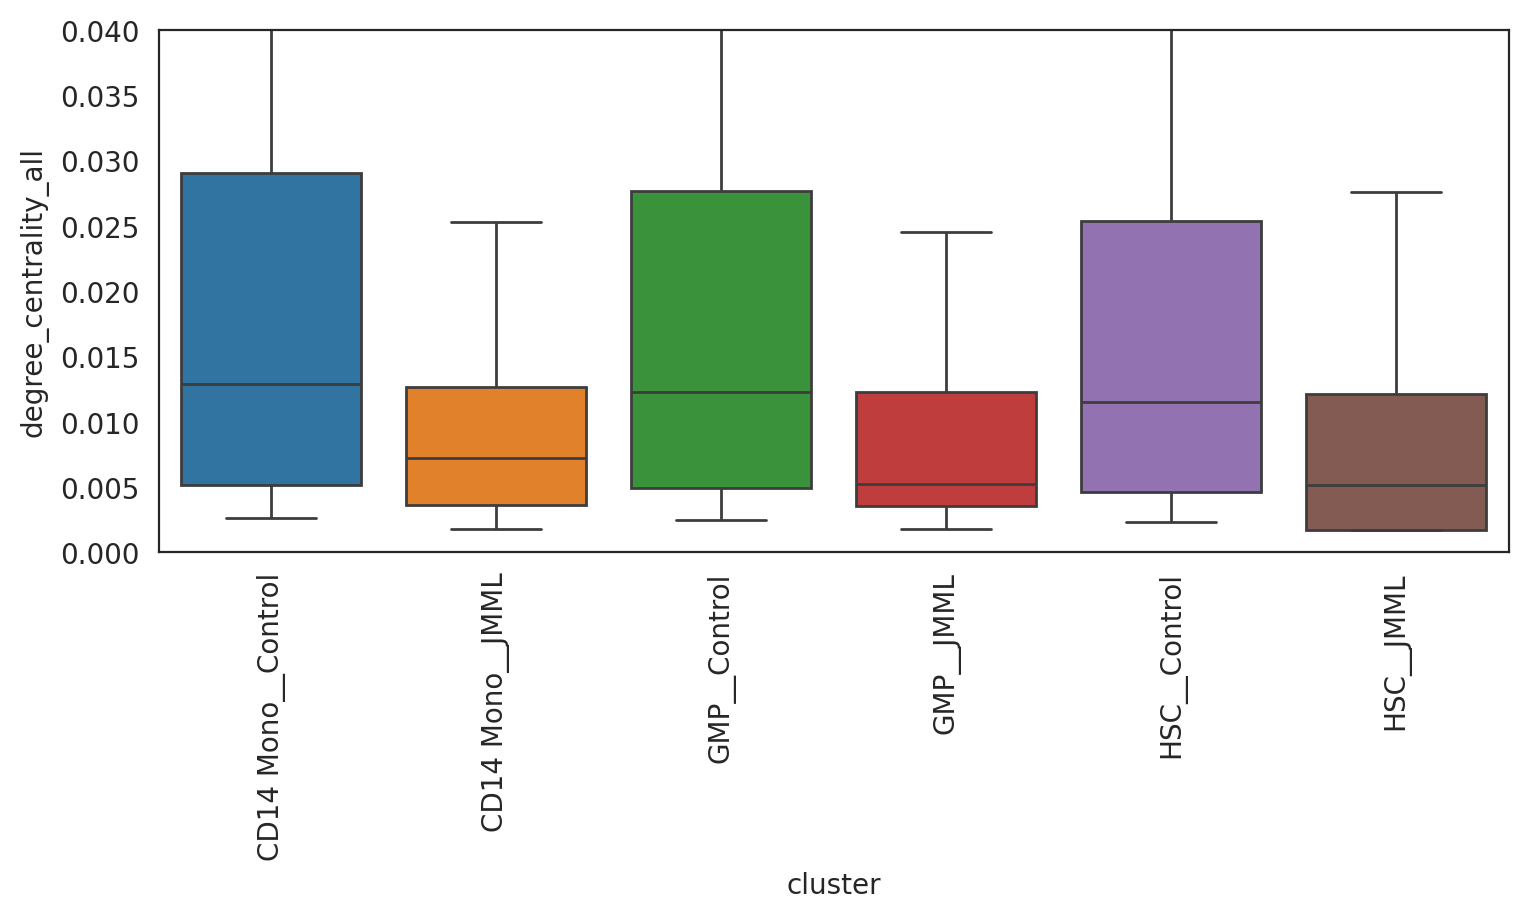

In [196]:
# Plot degree_centrality
plt.subplots_adjust(left=0.15, bottom=0.3)
plt.ylim([0,0.040])
links_condition.plot_score_discributions(values=["degree_centrality_all"], 
                               method="boxplot", 
                               # save=f"{save_folder}",
                              )

eigenvector_centrality


/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/seaborn/categorical.py:1622: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  hue_order = p._palette_without_hue_backcompat(palette, hue_order)
/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/seaborn/categorical.py:1626: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  p.map_hue(palette=palette, order=hue_order, norm=hue_norm, saturation=saturation)


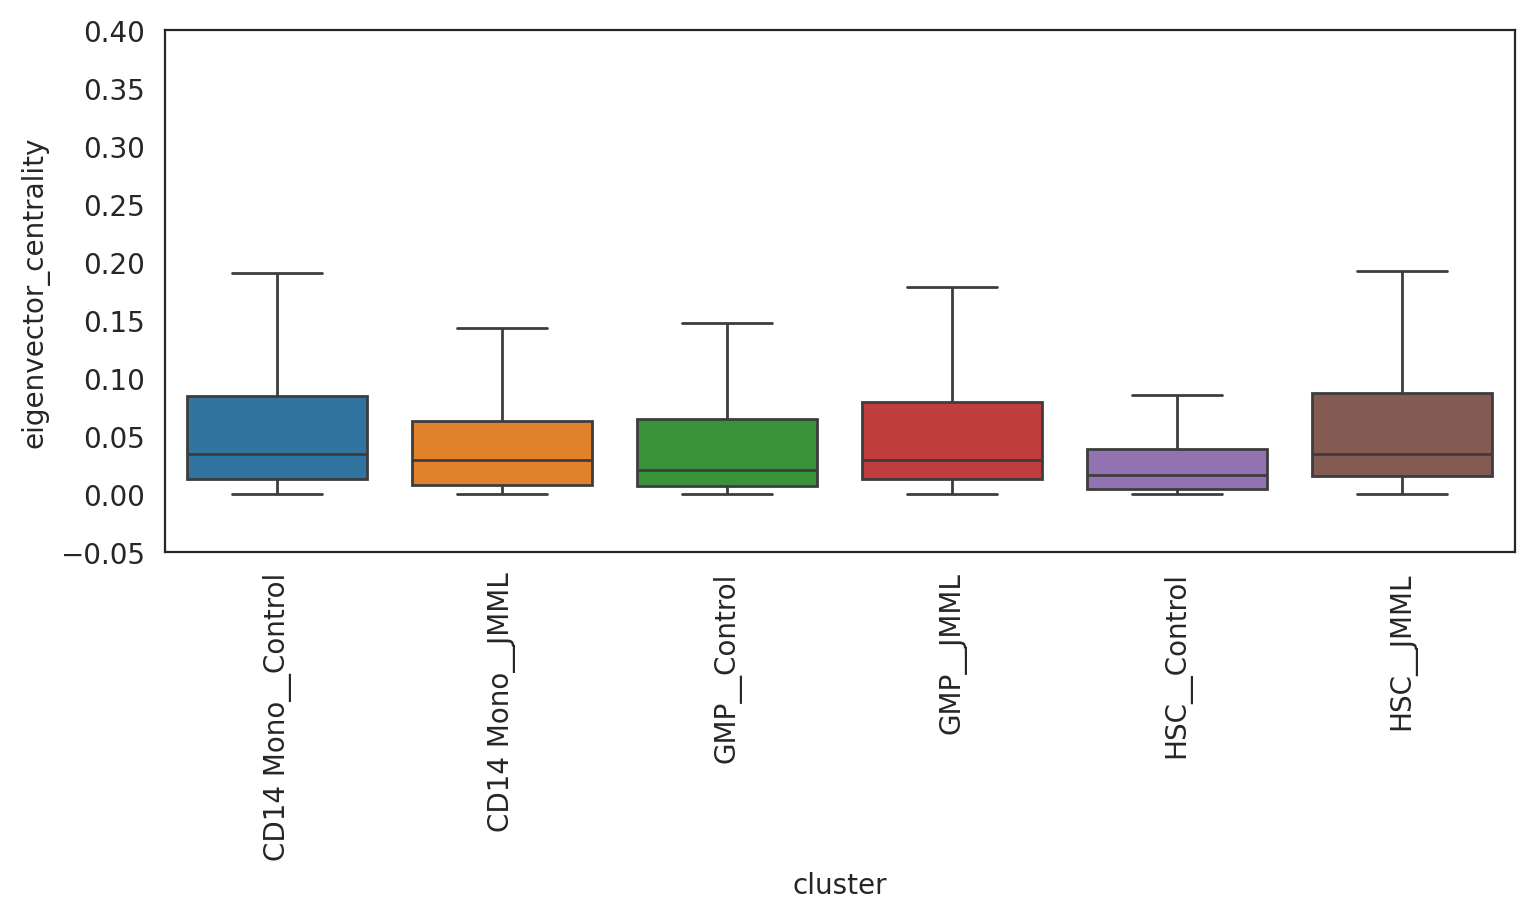

In [202]:
# Plot degree_centrality
plt.subplots_adjust(left=0.15, bottom=0.3)
plt.ylim([-0.05,0.40])
links_condition.plot_score_discributions(values=["eigenvector_centrality"], 
                               method="boxplot", 
                               # save=f"{save_folder}",
                              )

# TF perturbation

In [46]:
oracle

Oracle object

Meta data
    celloracle version used for instantiation: 0.22.0
    n_cells: 16045
    n_genes: 3000
    cluster_name: celltype_l2_merged
    dimensional_reduction_name: X_umap
    n_target_genes_in_TFdict: 27150 genes
    n_regulatory_in_TFdict: 1094 genes
    n_regulatory_in_both_TFdict_and_scRNA-seq: 137 genes
    n_target_genes_both_TFdict_and_scRNA-seq: 2582 genes
    k_for_knn_imputation: 401
Status
    Gene expression matrix: Ready
    BaseGRN: Ready
    PCA calculation: Done
    Knn imputation: Done
    GRN calculation for simulation: Not finished

In [12]:
# # You can load files with the following command.
# links = co.load_hdf5(file_path="links.celloracle.links")

## Make predictive models for simulation

In [47]:
links.filter_links()
oracle.get_cluster_specific_TFdict_from_Links(links_object=links)
oracle.fit_GRN_for_simulation(alpha=10,
                              use_cluster_specific_TFdict=True)

  0%|          | 0/3 [00:00<?, ?it/s]

## In silico TF perturbation analysis

/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/matplotlib/__init__.py:1446: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  return func(ax, *map(sanitize_sequence, args), **kwargs)


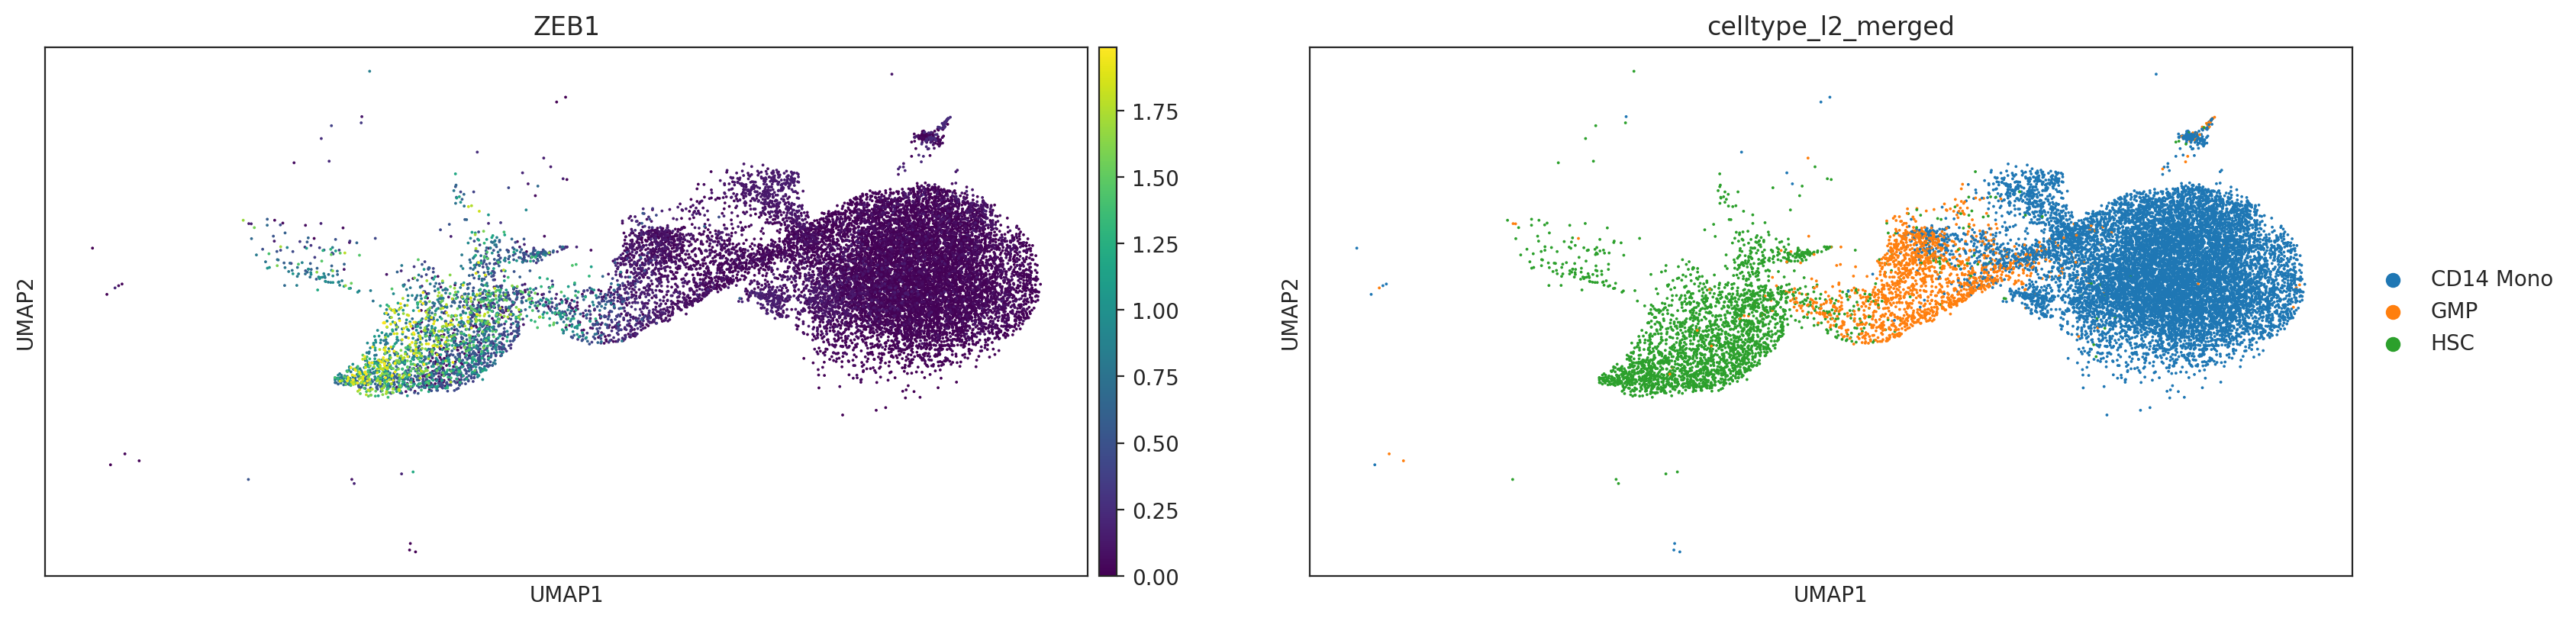

In [48]:
# Check gene expression
goi = "ZEB1"
sc.pl.umap(oracle.adata, color=[goi, oracle.cluster_column_name],
                 layer="imputed_count", use_raw=False, cmap="viridis")

/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/anndata/utils.py:235: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  warnings.warn(


AnnData object with n_obs × n_vars = 16045 × 3000
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_1.0', 'leiden_0.6', 'leiden_0.4', 'leiden_1.4', 'cell_type', 'celltype_l1_predicted', 'l1_prediction_score', 'celltype_l2_predicted', 'l2_prediction_score', 'leiden_1.5', 'leiden_0.8', 'leiden_1.2', 'batch', 'sample_groups', 'sample_celltype_l1', 'sample_celltype_l2', 'group_celltype_l1', 'group_celltype_l2', 'sample_groups_wide', 'group_celltype_l3', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'rawrna.size', 'rawprot.size', 'n.gene', 'mt.prop', 'drop.class', 'cnts_per_cell_RNA', 'cnts_per_cell_ADT', 'log2_counts_RNA', 'log2_features_RNA', 'log2_counts_ADT', 'log2_features_ADT', 'percent_mito', 'status', 'assignment', 'lib.gen', 'class_sum', 'class', 'score_mean', 'individual', 'age', 'enrichment', 'nCount_ADT', 'nFeature_ADT', 'nCount_SCT', 'nFeature_SCT', 'integrated.sct.clust

/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/matplotlib/__init__.py:1446: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  return func(ax, *map(sanitize_sequence, args), **kwargs)
/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/matplotlib/__init__.py:1446: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  return func(ax, *map(sanitize_sequence, args), **kwargs)
/opt/conda/envs/celloracle_020/lib/python3.10/site-packages/matplotlib/__init__.py:1446: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  return func(ax, *map(sanitize_sequence, args), **kwargs)


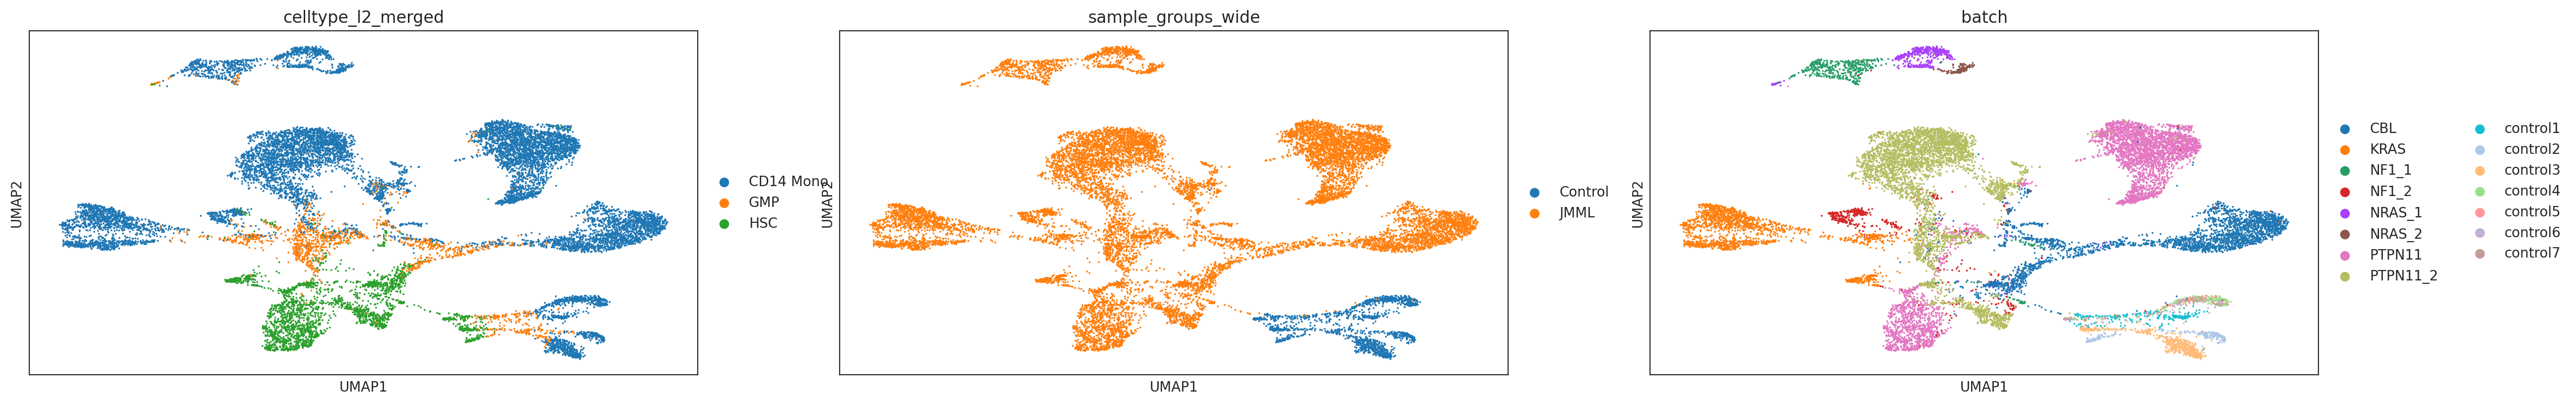

In [49]:
CELLTYPE_COL = "celltype_l2_merged"

selected_mask = (
    adata.obs[CELLTYPE_COL].isin(["HSC", "GMP", "CD14 Mono"])
    & adata.obs["sample_groups_wide"].isin(["Control", "JMML"])
)

# Все гены выбранных клеток: нормализуем до отбора HVG
adata_selected = adata[selected_mask.to_numpy(), :]

adata_umap = ad.AnnData(
    X=adata_selected.layers["counts"].copy(),
    obs=adata_selected.obs.copy(),
    var=adata_selected.var.copy(),
)

adata_umap.obs_names_make_unique()

# Сохраняем настоящие counts
adata_umap.layers["counts"] = adata_umap.X.copy()

# Подготовка экспрессии только для PCA/UMAP
sc.pp.normalize_total(adata_umap, target_sum=1e4)
sc.pp.log1p(adata_umap)

# Оставляем HVG по исходным меткам — НЕ пересчитываем
adata_umap = adata_umap[
    :, adata_umap.var["highly_variable"].fillna(False).astype(bool)
].copy()

# Отдельный объект для CellOracle: в X исходные counts
adata_co = ad.AnnData(
    X=adata_umap.layers["counts"].copy(),
    obs=adata_umap.obs.copy(),
    var=adata_umap.var.copy(),
)
adata_co.layers["counts"] = adata_co.X.copy()

# PCA на нормализованной, log1p и масштабированной экспрессии
sc.pp.scale(adata_umap, max_value=10)

sc.tl.pca(
    adata_umap,
    n_comps=50,
    svd_solver="arpack",
    random_state=0,
)

# Новый граф соседей только для выбранных клеток
sc.pp.neighbors(
    adata_umap,
    use_rep="X_pca",
    n_pcs=30,
    n_neighbors=30,
    random_state=0,
)

# Новый UMAP
sc.tl.umap(
    adata_umap,
    min_dist=0.3,
    random_state=0,
)

# Переносим координаты в объект для CellOracle
adata_co.obsm["X_umap"] = adata_umap.obsm["X_umap"].copy()

print(adata_co)

sc.pl.umap(
    adata_co,
    color=[CELLTYPE_COL, "sample_groups_wide", "batch"],
)

In [50]:
# # Plot gene expression in histogram
# sc.get.obs_df(oracle.adata, keys=[goi], layer="imputed_count").hist()
# plt.show()

### To simulate gene KO, we will set gene expression to 0.

In [51]:
# Enter perturbation conditions to simulate signal propagation after the perturbation.
oracle.simulate_shift(perturb_condition={goi: 0.0},
                      n_propagation=3)

In [52]:
# Get transition probability
oracle.estimate_transition_prob(n_neighbors=200,
                                knn_random=True,
                                sampled_fraction=1)

# Calculate embedding
oracle.calculate_embedding_shift(sigma_corr=0.05)

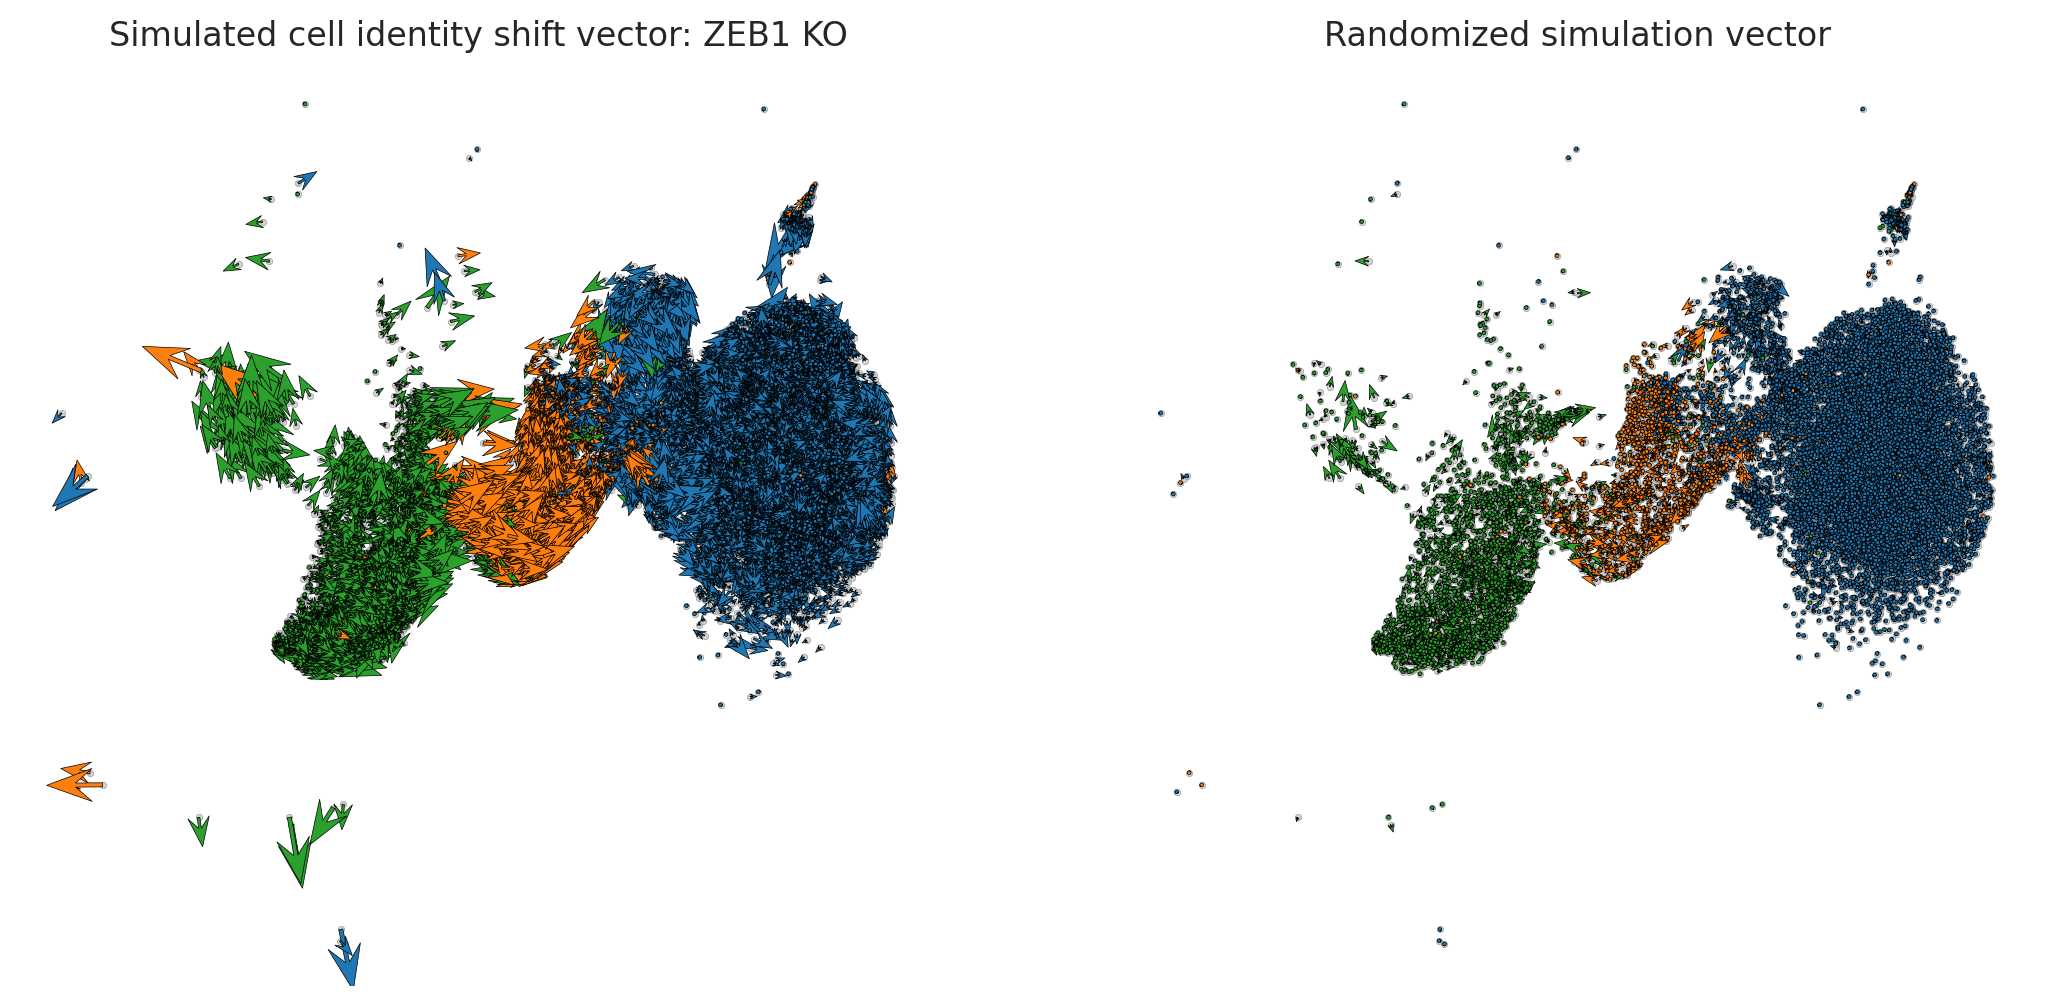

In [53]:
fig, ax = plt.subplots(1, 2,  figsize=[13, 6])

scale = 25
# Show quiver plot
oracle.plot_quiver(scale=scale, ax=ax[0])
ax[0].set_title(f"Simulated cell identity shift vector: {goi} KO")

# Show quiver plot that was calculated with randomized graph.
oracle.plot_quiver_random(scale=scale, ax=ax[1])
ax[1].set_title(f"Randomized simulation vector")

plt.show()

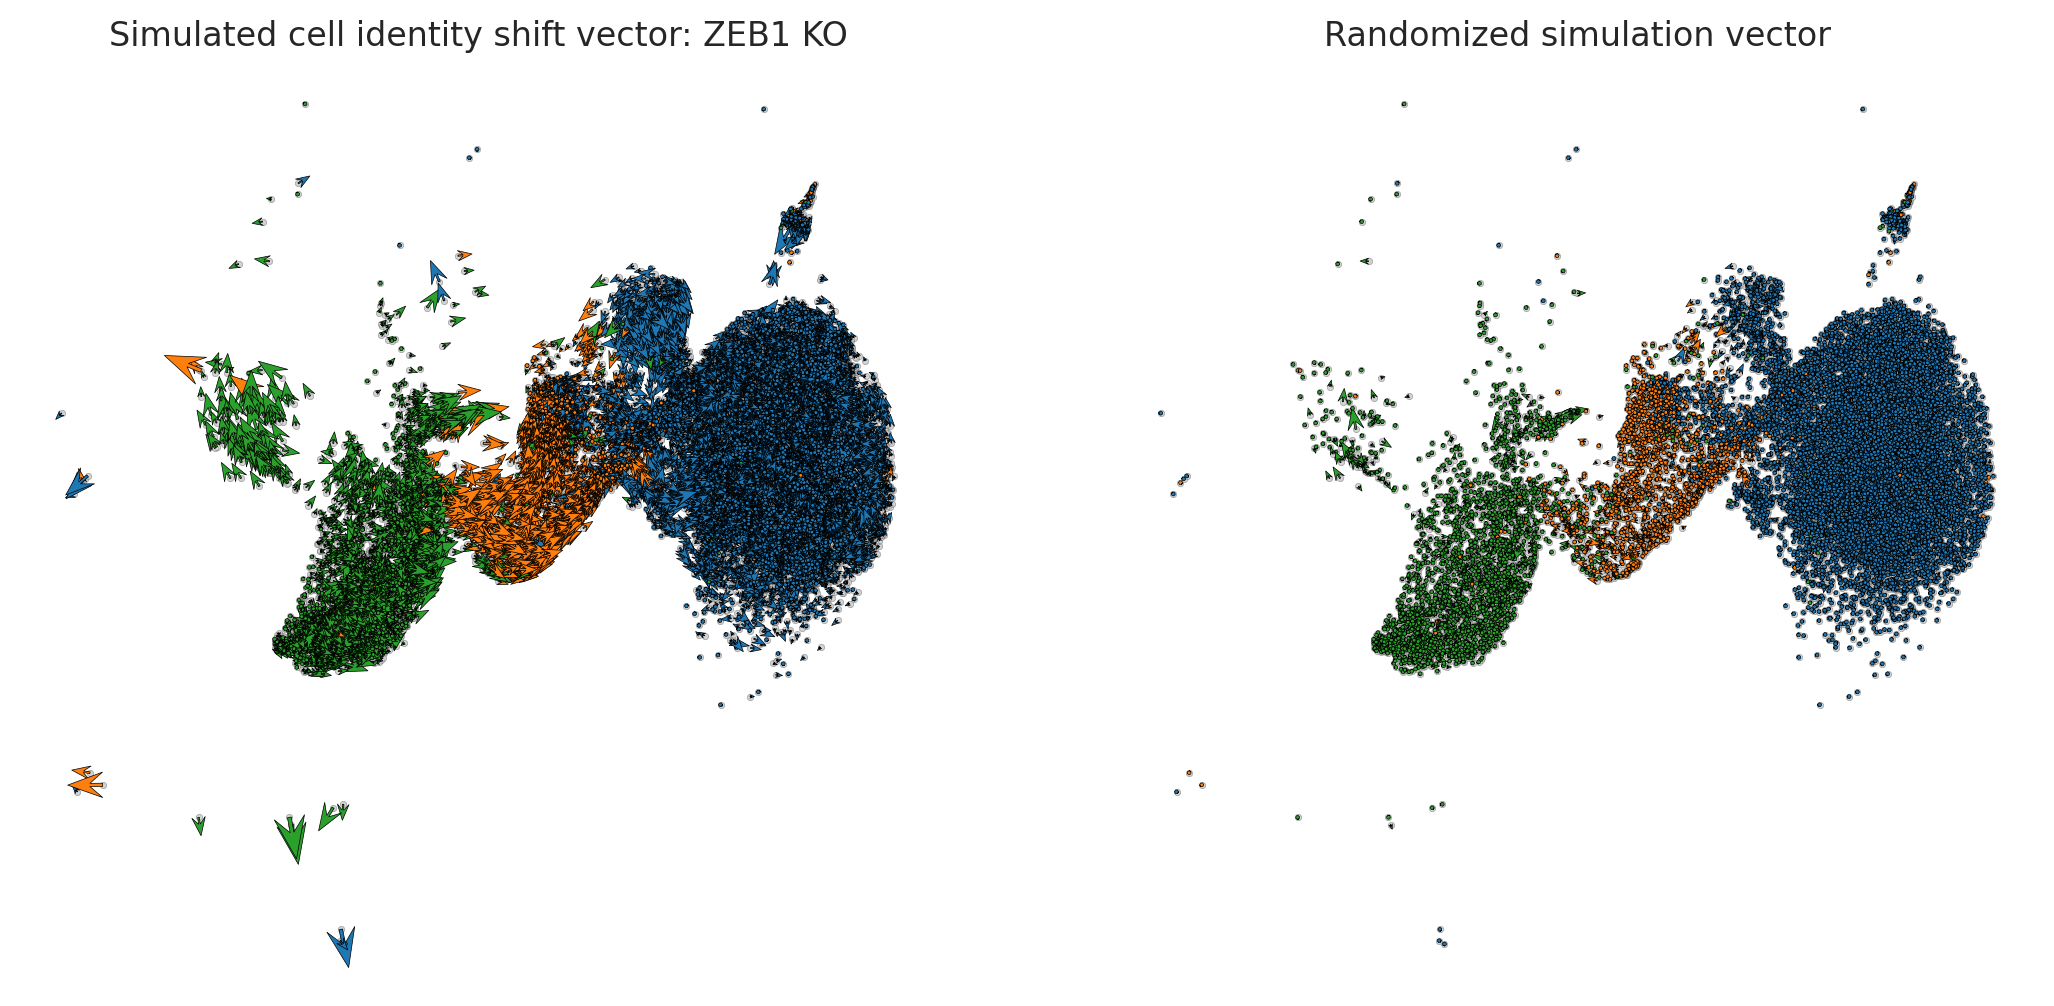

In [92]:
fig, ax = plt.subplots(1, 2,  figsize=[13, 6])

scale = 40
# Show quiver plot
oracle.plot_quiver(scale=scale, ax=ax[0])
ax[0].set_title(f"Simulated cell identity shift vector: {goi} KO")

# Show quiver plot that was calculated with randomized graph.
oracle.plot_quiver_random(scale=scale, ax=ax[1])
ax[1].set_title(f"Randomized simulation vector")

plt.show()